In [1]:
import logging
logging.getLogger("matplotlib").setLevel(logging.INFO)
import math
import os
from pathlib import Path

from huggingface_hub import snapshot_download
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style("white")
from sklearn.metrics import roc_auc_score, roc_curve
import SimpleITK as sitk
import torch
import torchvision
torchvision.disable_beta_transforms_warning()
from tqdm.auto import tqdm

import sys
sys.path.insert(0, str(Path.cwd().parent))  # repo root, for experiment_config / dataloader / models
from experiment_config import config
from dataloader import get_data_loader
from finetune import make_weights_for_balanced_classes

import matplotlib

# Re-add the missing _get method to RcParams if it doesn't exist
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = lambda self, key: self.get(key)

import matplotlib.pyplot as plt

torch.manual_seed(config.SEED)

data_dir = "/datasets/slow/LUNA25"
workspace_root = "/models/hiera-luna25"

results_dir = "/mode"

annotations_csv_path = Path(f"{data_dir}/LUNA25_Public_Training_Development_Data.csv")
# the folder containing the 5-fold predictions, either separate files in 5 subfolders (after training) or a single file ("all_folds_predictions.csv")
predictions_dir = Path(f"{workspace_root}/results/finetune-hiera-3D-20260814")
predictions_csv_path = predictions_dir / "all_folds_predictions.csv"
# the folder to save plots and statistics
figures_dir = Path(f"{workspace_root}/figures")
figures_dir.mkdir(exist_ok=True)
# the following folders and files will be downloaded and/or created if non-existing; don't change
dataset_dir = Path("/datasets/slow/LUNA25/LUNA25-MedSAM2")
segmentations_dir = dataset_dir / "instance-labels"
volumes_csv_path = Path(f"{workspace_root}/mask_volumes.csv")
radiomics_csv_path = Path(f"{data_dir}/additional-annotations/csv-annotations/radiomics.csv")
radiomics_figures_dir = figures_dir / "radiomics"
radiomics_figures_dir.mkdir(exist_ok=True)

# Download

In [2]:
# https://huggingface.co/datasets/wanglab/LUNA25-MedSAM2
if not dataset_dir.exists():
    local_path = snapshot_download(
      repo_id="wanglab/LUNA25-MedSAM2",
      repo_type="dataset",
      local_dir=dataset_dir
    )
print(f"Segmentations are avaialble at {segmentations_dir}")

Segmentations are avaialble at /datasets/slow/LUNA25/LUNA25-MedSAM2/instance-labels


# Analyze

## Nodule Volumes

In [3]:
def calculate_mask_volumes(folder_path):
    """
    Calculates the volume (in mm^3) of segmentation masks in NIfTI files
    within a given folder and stores the results in a DataFrame.

    Assumes the files are named logically (e.g., ending with .nii.gz).
    The volume is calculated by counting non-zero voxels and multiplying
    by the volume of a single voxel (determined from the image's spacing).

    Args:
        folder_path (str or Path): The path to the folder containing .nii.gz files.

    Returns:
        pd.DataFrame: A DataFrame with columns "filename" and "volume_mm3".
                      Returns None if no .nii.gz files are found.
    """
    folder_path = Path(folder_path)
    nii_files = list(folder_path.glob("*.nii.gz"))
    if not nii_files:
        print(f"No .nii.gz files found in the folder {folder_path}")
        return None

    results = []
    for file_path in tqdm(nii_files):
        filename = file_path.name
        try:
            image = sitk.ReadImage(str(file_path))
            data = sitk.GetArrayFromImage(image)
            voxel_spacing = image.GetSpacing()

            if np.any(np.array(voxel_spacing) <= 0):
                print(f"Warning: Invalid voxel dimensions {voxel_spacing} found in {filename}. Skipping file.")
                results.append({"filename": filename, "volume_mm3": np.nan})
                continue

            voxel_volume_mm3 = np.prod(voxel_spacing)
            num_mask_voxels = np.count_nonzero(data)
            if num_mask_voxels == 0:
                print(f"Warning: File '{filename}' has 0 non-zero mask voxels.")
            total_volume_mm3 = num_mask_voxels * voxel_volume_mm3
            results.append({"filename": filename, "volume_mm3": total_volume_mm3})
        except Exception as e:
            print(f"Error processing file {filename}: {e}")
            results.append({"filename": filename, "volume_mm3": np.nan})

    df_results = pd.DataFrame(results)
    return df_results

if not volumes_csv_path.exists():
    df_volumes = calculate_mask_volumes(segmentations_dir)
    if df_volumes is not None:
        df_volumes.to_csv(volumes_csv_path, index=False)
print(f"Mask volumes are avaialble at {volumes_csv_path}")

Mask volumes are avaialble at /models/hiera-luna25/mask_volumes.csv


In [4]:
df_volumes = pd.read_csv(volumes_csv_path)
df_annotations = pd.read_csv(annotations_csv_path)
df_volumes["SeriesInstanceUID"] = df_volumes["filename"].str.replace(".nii.gz", "", regex=False)
df_volumes["volume_percentile"] = df_volumes["volume_mm3"].rank(pct=True, method="average").round(4)
df_volumes["sphere_radius_mm"] = ((3 * df_volumes["volume_mm3"]) / (4 * math.pi)) ** (1/3)
df_annotations_volumes = pd.merge(df_annotations, df_volumes, on="SeriesInstanceUID", how="left")
df_annotations_volumes.drop(["filename"], axis=1, inplace=True)
display(df_annotations_volumes.head())
df_annotations_volumes[["volume_mm3", "sphere_radius_mm"]].describe()

,PatientID,SeriesInstanceUID,StudyDate,CoordX,CoordY,CoordZ,LesionID,AnnotationID,NoduleID,label,Age_at_StudyDate,Gender,volume_mm3,volume_percentile,sphere_radius_mm
0,100570,1.2.840.113654.2.55.32380467633296345717423514...,19990102,61.14,-163.28,-177.75,1,100570_1_19990102,100570_1,1,63,Male,5504.687500,0.9429,10.953377
1,106364,1.2.840.113654.2.55.16930993607533226779708566...,19990102,30.64,-95.96,-128.59,1,106364_1_19990102,106364_1,1,67,Female,690.069580,0.7414,5.481946
2,127302,1.2.840.113654.2.55.13728437630416839550344528...,20000102,-82.53,-27.85,-209.46,1,127302_1_20000102,127302_1,1,61,Male,1799.560547,0.8674,7.545580
3,128899,1.2.840.113654.2.55.40415300708683206534849072...,20010102,-38.69,-8.78,-39.43,1,128899_1_20010102,128899_1,1,64,Male,393.610663,0.6337,4.546314
4,215816,1.3.6.1.4.1.14519.5.2.1.7009.9004.241362276021...,19990102,32.89,-37.98,-100.04,1,215816_1_19990102,215816_1,1,69,Female,1584.692806,0.8543,7.232451


,volume_mm3,sphere_radius_mm
count,6141.000000,6141.000000
mean,1873.088211,5.185258
std,8078.456046,3.450220
min,5.234299,1.077101
25%,128.967940,3.134231
50%,308.020278,4.189513
75%,841.412672,5.856527
max,241810.113309,38.648142


### Volume vs Label

Histogram saved to /models/hiera-luna25/figures/volume_mm3_by_label_all_folds.png


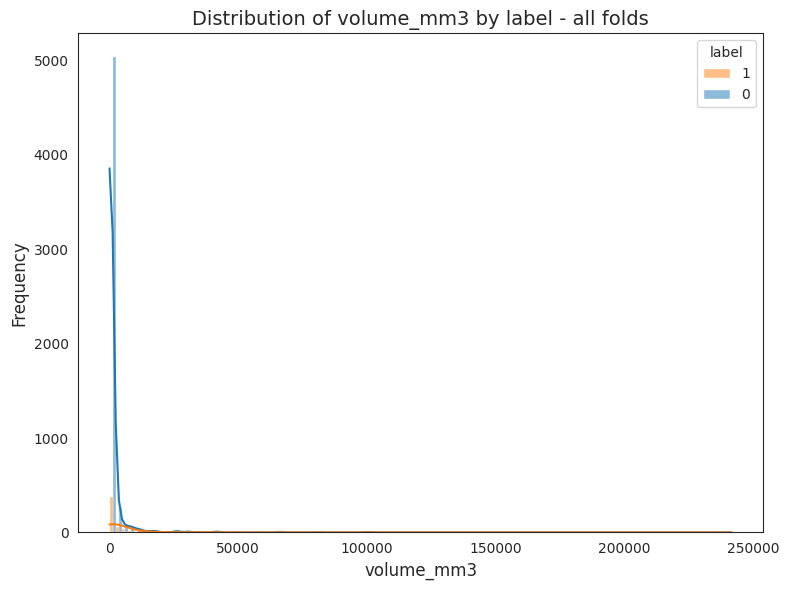

Histogram saved to /models/hiera-luna25/figures/top_95th_percentile_volume_mm3_by_label_all_folds.png


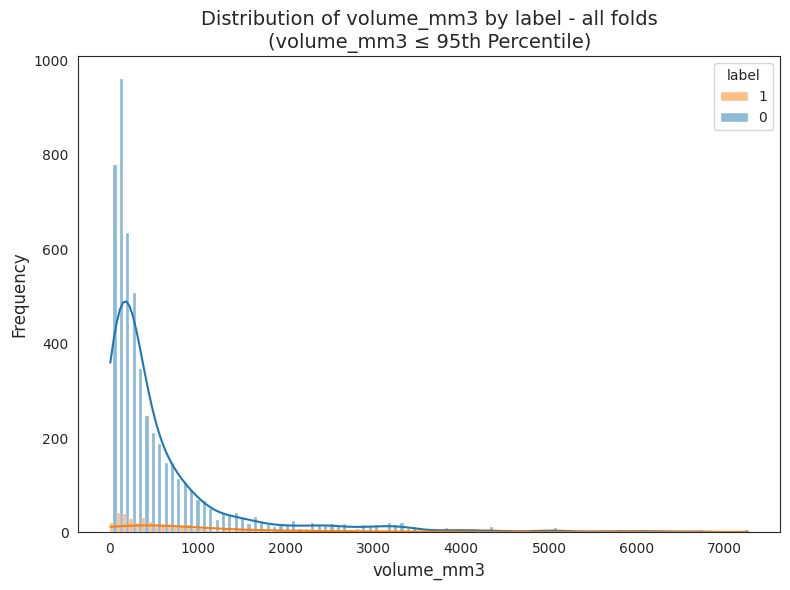

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_all_folds.png


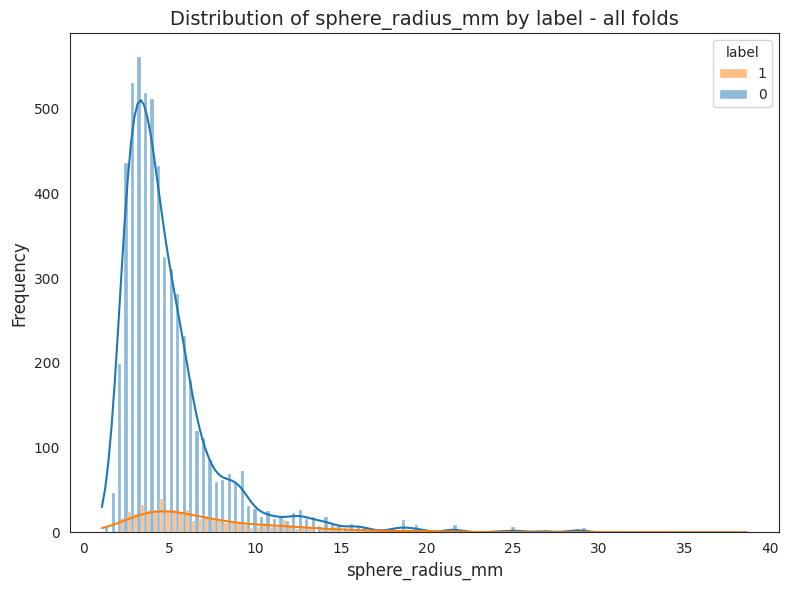

Histogram saved to /models/hiera-luna25/figures/top_95th_percentile_sphere_radius_mm_by_label_all_folds.png


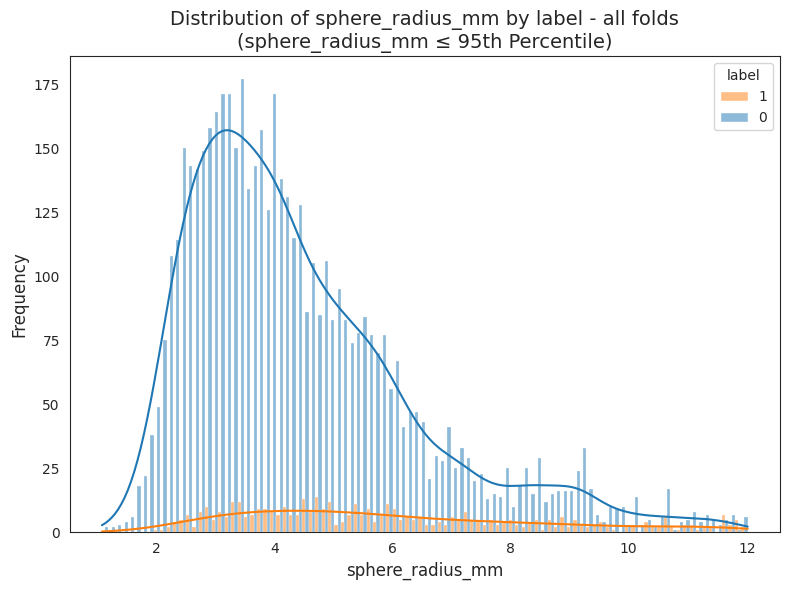

In [5]:
def plot_histogram_by_column(df, column_to_plot="volume_mm3", column_to_label="label", use_top_95th_percentile=False, plot_label="all folds", bins=100, save_plot=True):
    """
    Creates a histogram of the target column separated by another column.

    Args:
        df (pd.DataFrame): The DataFrame containing `column_to_plot` and `column_to_label`.
        column_to_plot (str, optional): The column to plot. Defaults to "volume_mm3".
        column_to_label (str, optional): The column to seperate the data by. Defaults to "label".
        use_top_95th_percentile (bool, optional): Whether to plot only the top 95th percentile of the data. Defaults to False.
        plot_label (str, optional): The label of the plot. Defaults to "all folds".
        bins (int, optional): Number of bins to use in the histogram. Defaults to 100.
        output_path (str or Path, optional): Path to save the plot.
    """
    plt.figure(figsize=(8, 6))

    df_plot = df.copy()
    df_plot[column_to_label] = df_plot[column_to_label].astype(str)

    if use_top_95th_percentile:
        column_95th_percentile = df_plot[column_to_plot].quantile(0.95)
        df_plot = df_plot[df_plot[column_to_plot] <= column_95th_percentile]

    default_palette = sns.color_palette()
    labels = sorted(df_plot[column_to_label].unique())
    color_mapping = {label: default_palette[i % len(default_palette)] for i, label in enumerate(labels)}

    sns.histplot(
        data=df_plot,
        x=column_to_plot,
        hue=column_to_label,
        palette=color_mapping,
        bins=bins,
        kde=True,
        multiple="dodge"
    )

    title = f"Distribution of {column_to_plot} by {column_to_label} - {plot_label}"
    if use_top_95th_percentile:
        title += f"\n({column_to_plot} ≤ 95th Percentile)"
    plt.title(title, fontsize=14)
    plt.xlabel(column_to_plot, fontsize=12)
    plt.ylabel("Frequency", fontsize=12)

    plt.tight_layout()
    if save_plot:
        save_name = f"{column_to_plot}_by_{column_to_label}_{plot_label.replace(' ', '_')}.png"
        if use_top_95th_percentile:
            save_name = "top_95th_percentile_" + save_name
        save_path = figures_dir / save_name
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Histogram saved to {save_path}")
    plt.show()

plot_histogram_by_column(df_annotations_volumes)
plot_histogram_by_column(df_annotations_volumes, use_top_95th_percentile=True)
plot_histogram_by_column(df_annotations_volumes, column_to_plot="sphere_radius_mm")
plot_histogram_by_column(df_annotations_volumes, column_to_plot="sphere_radius_mm", use_top_95th_percentile=True)

## Predictions

In [6]:
if not predictions_csv_path.exists():
    df_predictions = pd.DataFrame()
    for fold in range(1, 6):
        fold_preds_csv_path = predictions_dir / f"fold_{fold}" / "predictions.csv"
        df_fold_preds = pd.read_csv(fold_preds_csv_path)
        df_fold_preds["fold"] = fold
        df_predictions = pd.concat([df_predictions, df_fold_preds])
    df_predictions.to_csv(predictions_csv_path, index=False)
print(f"Predictions are avaialble at {predictions_csv_path}")

Predictions are avaialble at /models/hiera-luna25/results/finetune-hiera-3D-20260814/all_folds_predictions.csv


In [7]:
df_predictions = pd.read_csv(predictions_csv_path)
df_annotations_volumes_predictions = pd.merge(df_annotations_volumes, df_predictions, on="AnnotationID", how="inner")
labels_match = df_annotations_volumes_predictions["label_x"] == df_annotations_volumes_predictions["label_y"]
if labels_match.all():
    df_annotations_volumes_predictions.drop(["label_y"], axis=1, inplace=True)
    df_annotations_volumes_predictions.rename(columns={"label_x": "label"}, inplace=True)
    df_annotations_volumes_predictions["absolute_error"] = abs(df_annotations_volumes_predictions["probability"] - df_annotations_volumes_predictions["label"])
    df_annotations_volumes_predictions.sort_values(by=["absolute_error"], inplace=True, ascending=False)
    display(df_annotations_volumes_predictions.head())
else:
    print(f"Error: Labels in annotations and predictions are not the same!")

,PatientID,SeriesInstanceUID,StudyDate,CoordX,CoordY,CoordZ,LesionID,AnnotationID,NoduleID,label,Age_at_StudyDate,Gender,volume_mm3,volume_percentile,sphere_radius_mm,probability,fold,absolute_error
1186,205447,1.3.6.1.4.1.14519.5.2.1.7009.9004.325441366194...,20010102,45.400000,-89.990000,-260.61,1,205447_1_20010102,205447_1,0,68,Female,5545.421072,0.9432,10.980328,0.904445,3,0.904445
1964,202392,1.3.6.1.4.1.14519.5.2.1.7009.9004.107194152627...,20000102,57.250000,63.700000,1709.20,3,202392_3_20000102,202392_3,0,71,Male,1831.570789,0.8681,7.590057,0.898967,3,0.898967
2999,209297,1.3.6.1.4.1.14519.5.2.1.7009.9004.281053541839...,20000102,-101.330376,60.959396,-211.25,1,209297_1_20000102,209297_1,1,69,Female,79.562534,0.1988,2.668128,0.101115,3,0.898885
3935,112981,1.2.840.113654.2.55.13489442392113785383008782...,20000102,67.000000,24.910000,-23.99,1,112981_1_20000102,112981_1,0,71,Male,674.231823,0.7365,5.439682,0.890208,3,0.890208
662,203473,1.3.6.1.4.1.14519.5.2.1.7009.9004.109872346282...,19990102,-78.300000,124.280000,-1420.58,1,203473_1_19990102,203473_1,0,58,Female,312.201555,0.5806,4.208385,0.887588,3,0.887588


### WeightedRandomSampler

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_1.png


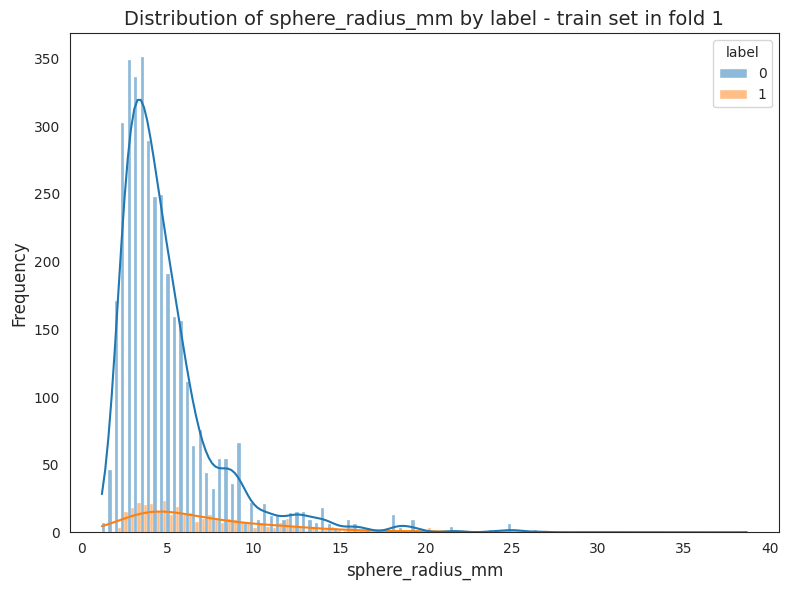

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_1_after_sampling.png


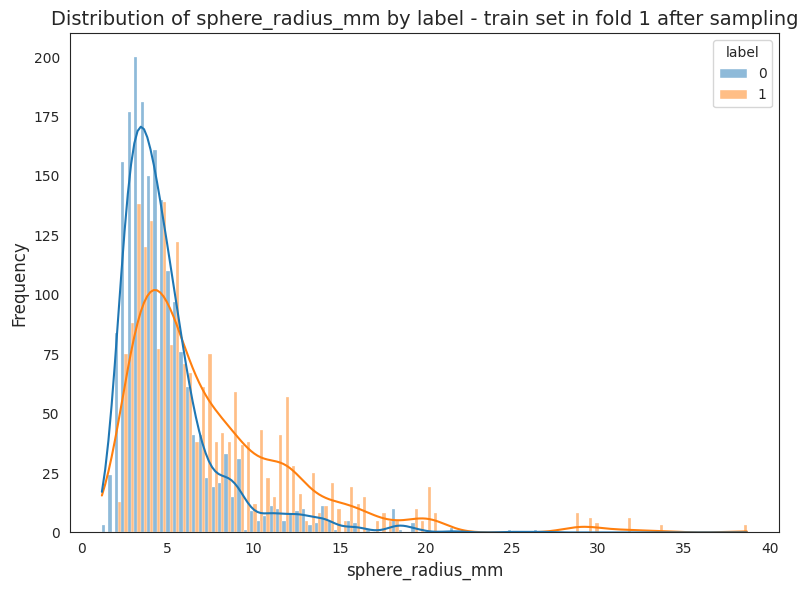

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_2.png


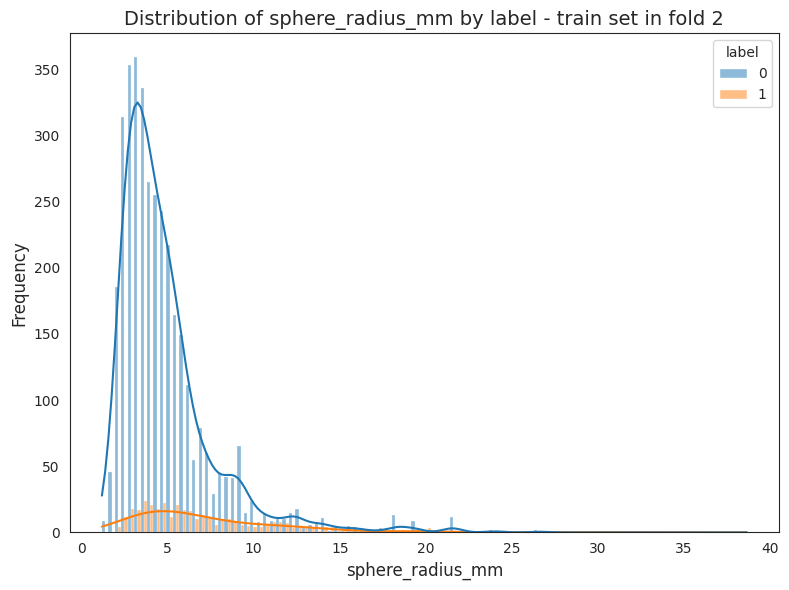

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_2_after_sampling.png


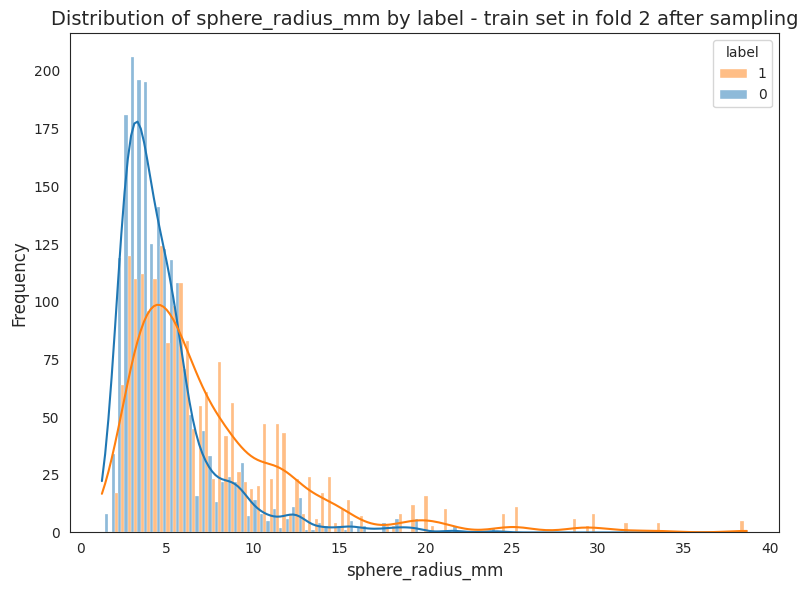

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_3.png


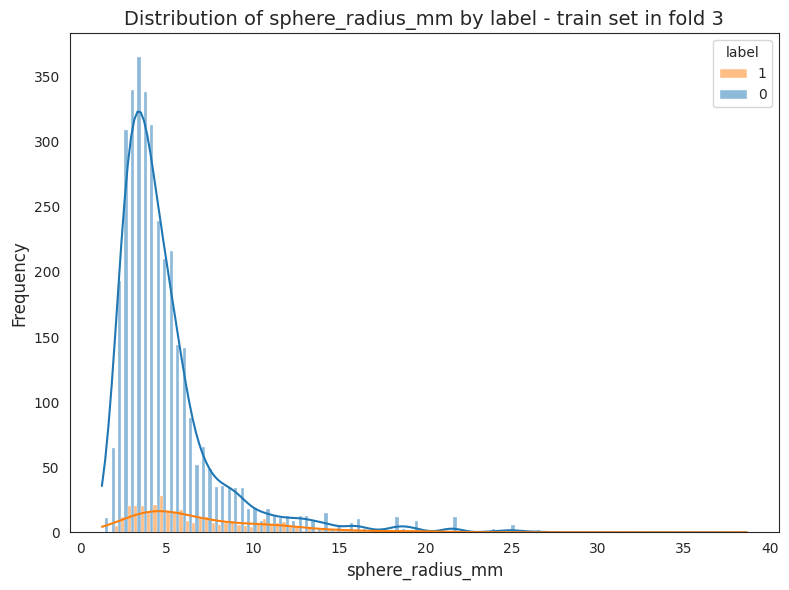

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_3_after_sampling.png


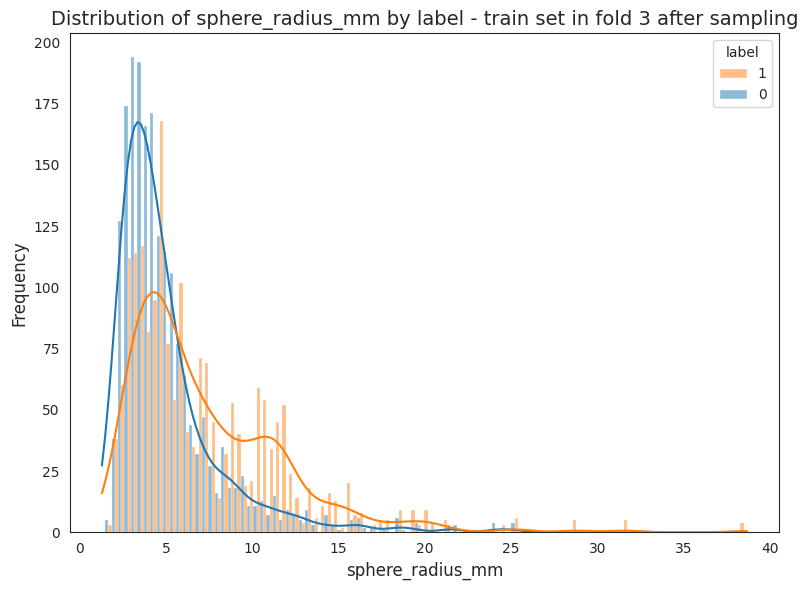

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_4.png


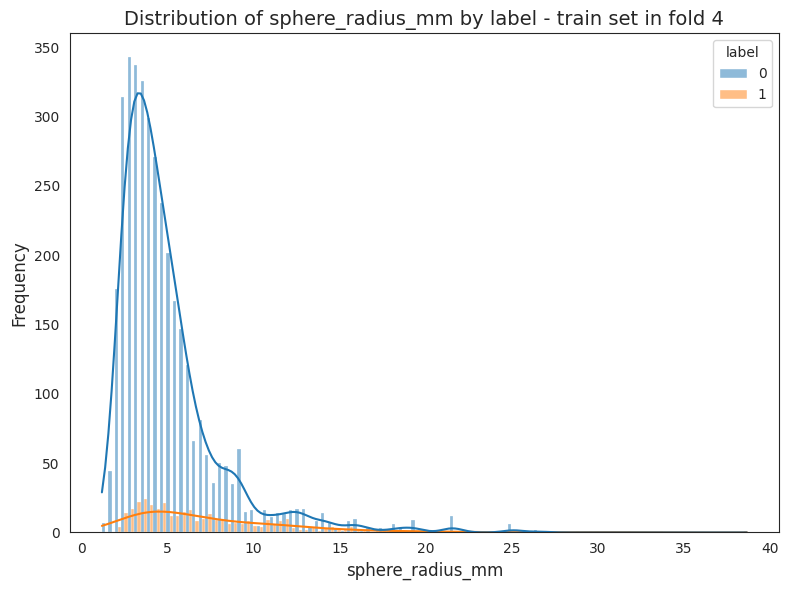

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_4_after_sampling.png


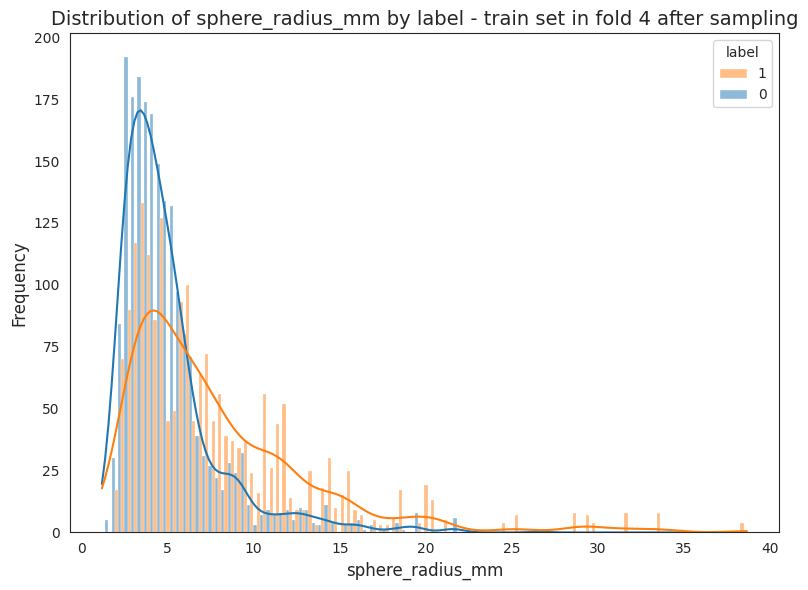

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_5.png


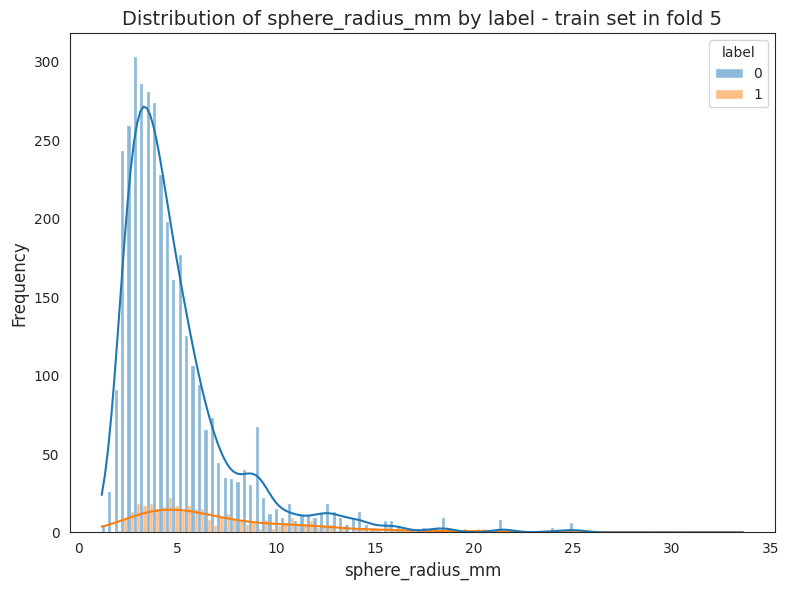

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_train_set_in_fold_5_after_sampling.png


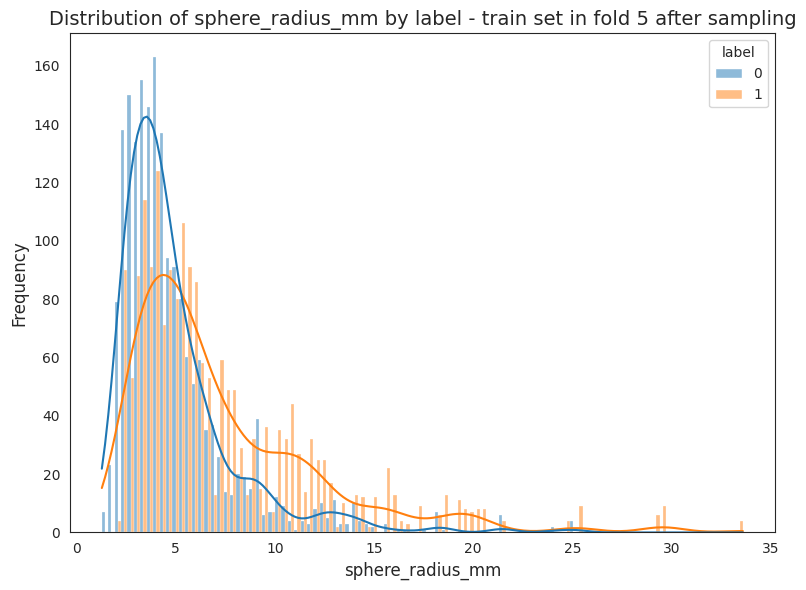

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_all_folds_before_sampling.png


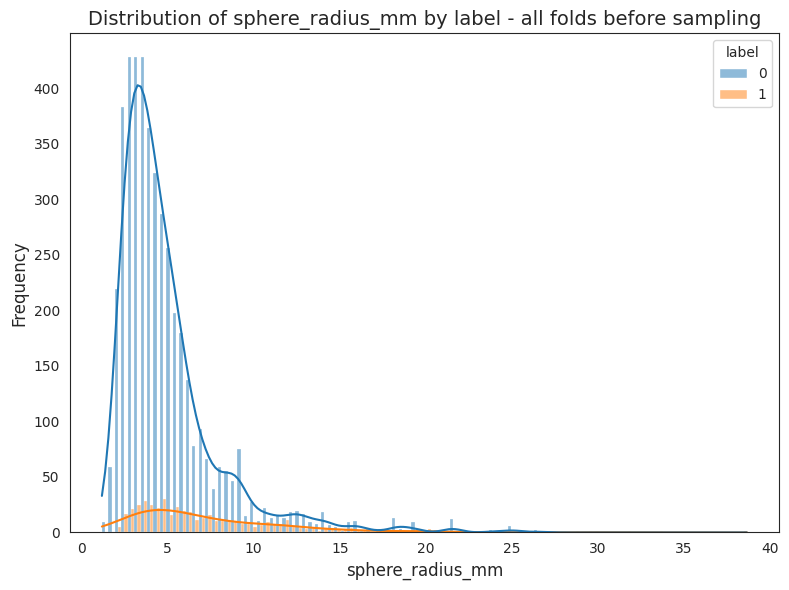

Histogram saved to /models/hiera-luna25/figures/sphere_radius_mm_by_label_all_folds_after_sampling.png


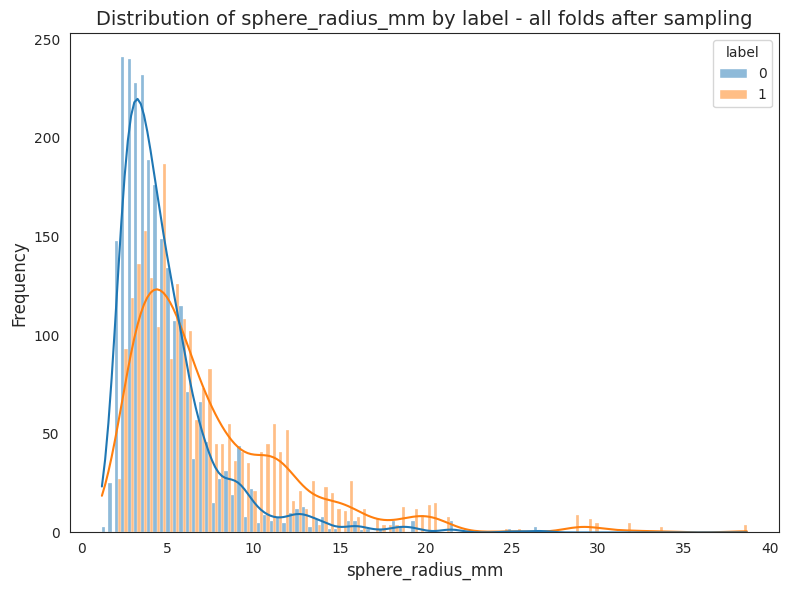

In [8]:
def plot_weighted_sampling_effect(df, plot_label):
    df_plot = df.copy()
    weights = make_weights_for_balanced_classes(df_plot["label"].values)
    weights = torch.DoubleTensor(weights)
    # note that this is not to reproduce the samples at finetuning time, but show the effect of sampling
    sampler = torch.utils.data.WeightedRandomSampler(weights=weights, num_samples=len(df_plot))
    sampled_indices = list(sampler)
    df_balanced = df_plot.iloc[sampled_indices].reset_index(drop=True)
    plot_histogram_by_column(df_balanced, column_to_plot="sphere_radius_mm", use_top_95th_percentile=False, plot_label=plot_label)

for fold in range(1, 6):
    df_val = df_annotations_volumes_predictions[df_annotations_volumes_predictions["fold"] == fold]
    df_val_annotation_ids = df_val["AnnotationID"].values
    df_train = df_annotations_volumes_predictions[~df_annotations_volumes_predictions["AnnotationID"].isin(df_val_annotation_ids)]
    plot_histogram_by_column(df_train, column_to_plot="sphere_radius_mm", use_top_95th_percentile=False, plot_label=f"train set in fold {fold}")
    plot_weighted_sampling_effect(df_train, plot_label=f"train set in fold {fold} after sampling")

plot_histogram_by_column(df_annotations_volumes_predictions, column_to_plot="sphere_radius_mm", use_top_95th_percentile=False, plot_label="all folds before sampling")
plot_weighted_sampling_effect(df_annotations_volumes_predictions, plot_label="all folds after sampling")


### Volume vs Absolute Error

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_all_folds.png


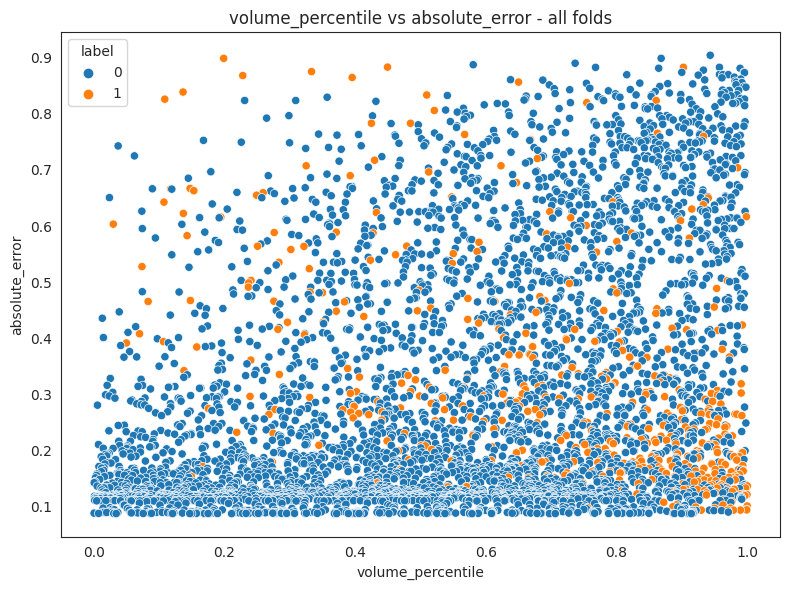

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_500_worst_predictions_in_all_folds.png
Worst predictions saved to /models/hiera-luna25/figures/500_worst_predictions_in_all_folds.csv


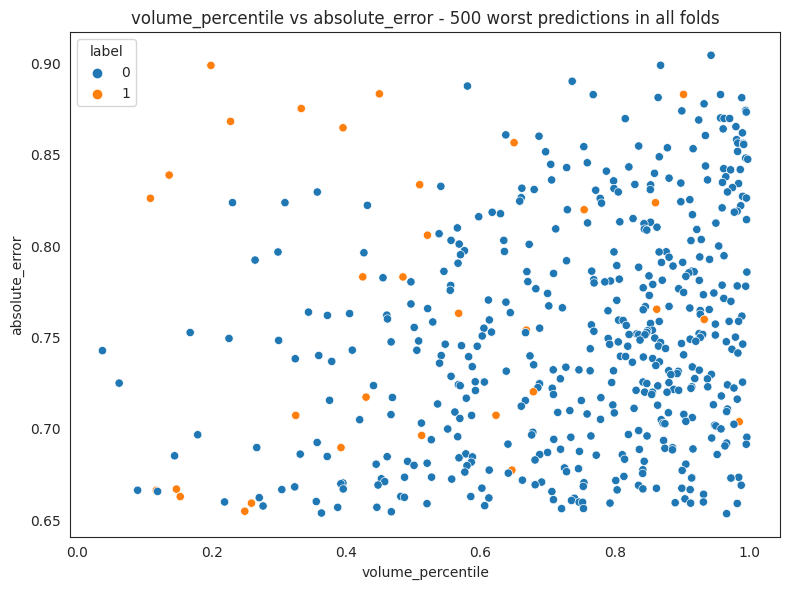

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_200_worst_predictions_in_fold_1.png
Worst predictions saved to /models/hiera-luna25/figures/200_worst_predictions_in_fold_1.csv


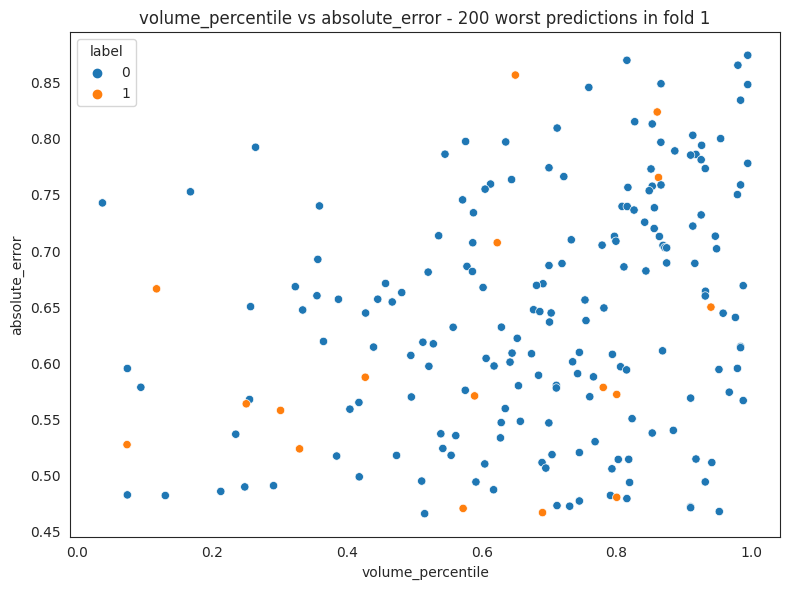

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_200_worst_predictions_in_fold_2.png
Worst predictions saved to /models/hiera-luna25/figures/200_worst_predictions_in_fold_2.csv


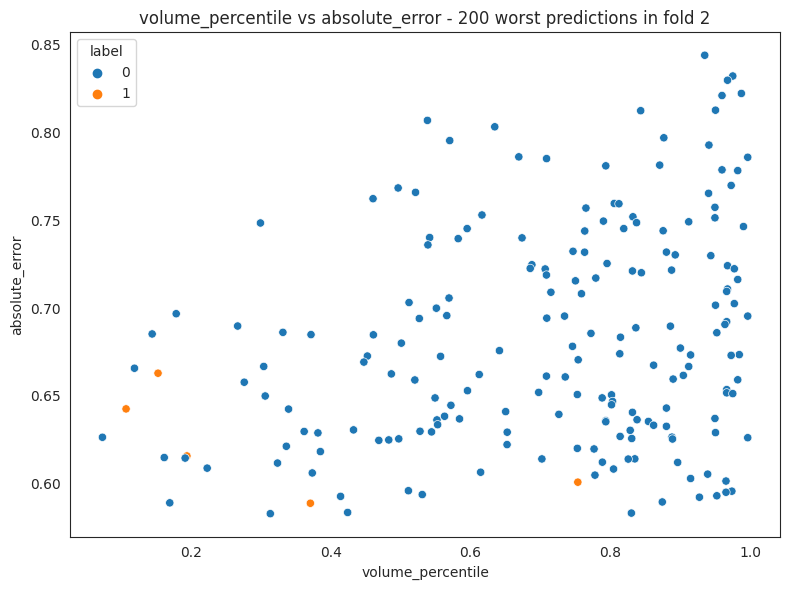

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_200_worst_predictions_in_fold_3.png
Worst predictions saved to /models/hiera-luna25/figures/200_worst_predictions_in_fold_3.csv


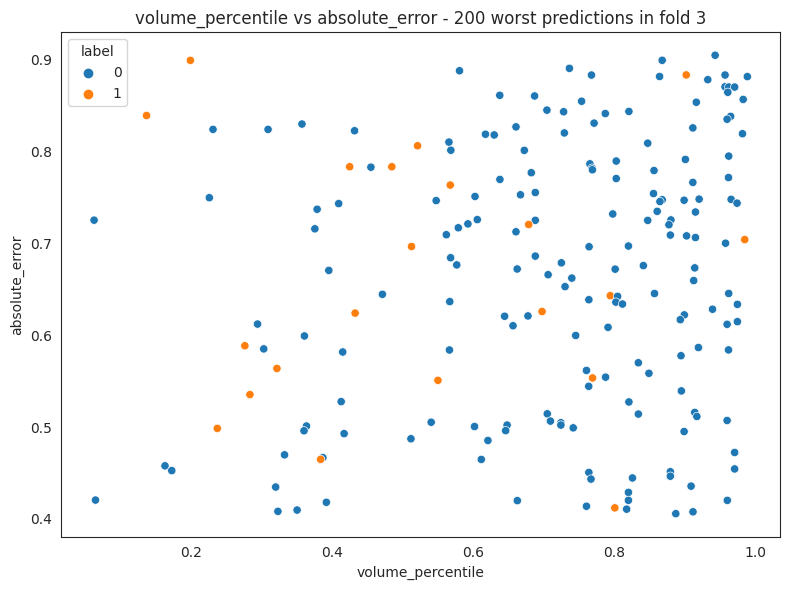

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_200_worst_predictions_in_fold_4.png
Worst predictions saved to /models/hiera-luna25/figures/200_worst_predictions_in_fold_4.csv


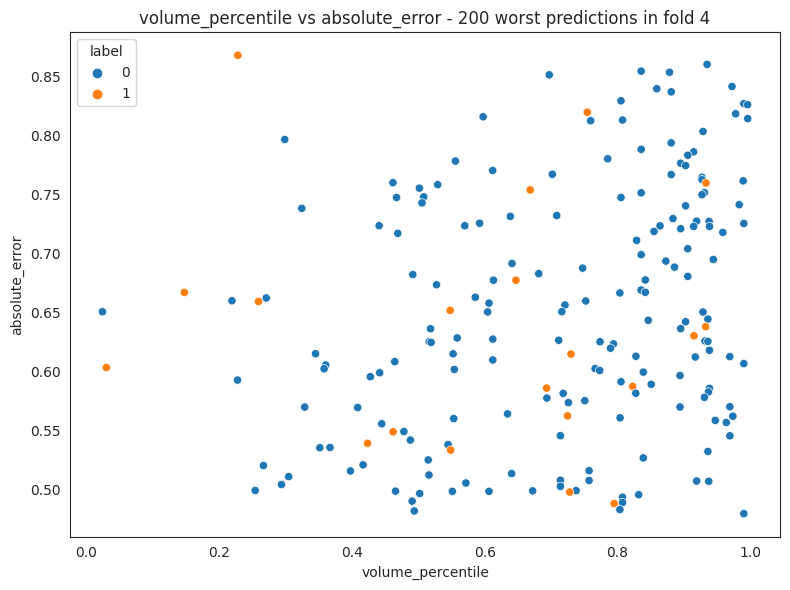

Scatterplot saved to /models/hiera-luna25/figures/error_volume_scatterplot_200_worst_predictions_in_fold_5.png
Worst predictions saved to /models/hiera-luna25/figures/200_worst_predictions_in_fold_5.csv


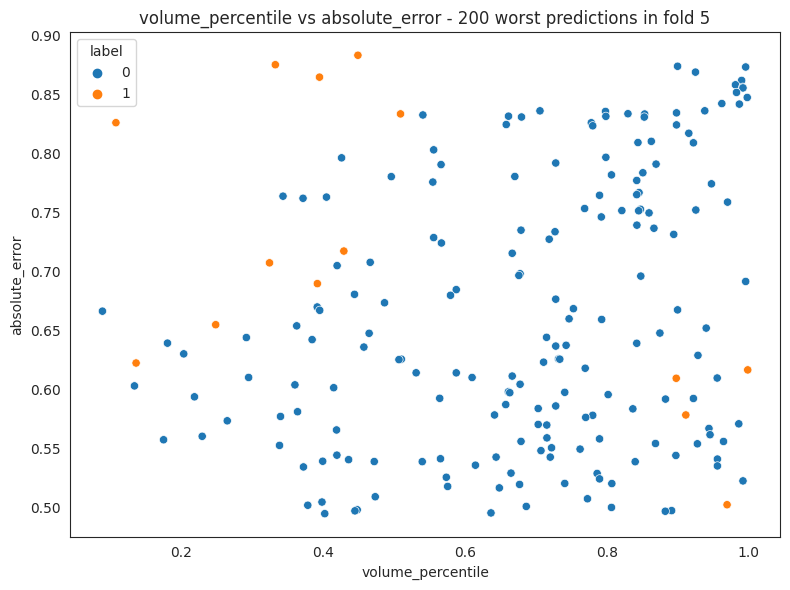

In [9]:
def plot_error_feature_distribution(df, x="volume_percentile", name="volume", num_worst_predictions=None, plot_label="all folds", save_dir=figures_dir, save_plot=True, save_worst_predictions=True):
    plt.figure(figsize=(8, 6))

    df_plot = df.dropna(subset=[x]).copy()
    if num_worst_predictions is not None:
        df_plot.sort_values(by=["absolute_error"], ascending=False, inplace=True)
        df_plot = df_plot[["AnnotationID", "label", x, "sphere_radius_mm", "absolute_error"]]
        df_plot = df_plot.head(num_worst_predictions)
        plot_label = f"{num_worst_predictions} worst predictions in {plot_label}"

    sns.scatterplot(data=df_plot, x=x, y="absolute_error", hue="label")
    plt.title(f"{x} vs absolute_error - {plot_label}")
    plt.xlabel(x)
    plt.ylabel("absolute_error")
    
    plt.tight_layout()
    if save_plot:
        save_path = save_dir / f"error_{name}_scatterplot_{plot_label.replace(' ', '_')}.png"
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Scatterplot saved to {save_path}")
    if save_worst_predictions and num_worst_predictions is not None:
        save_path = save_dir / f"{plot_label.replace(' ', '_')}.csv"
        df_plot.to_csv(save_path, index=False)
        print(f"Worst predictions saved to {save_path}")
    plt.show()

num_worst_predictions_all_folds = 500
num_worst_predictions_one_fold = 200
# plot_histogram_by_column(df_annotations_volumes_predictions, column_to_plot="absolute_error", column_to_label="fold", use_top_95th_percentile=False, bins=10)
plot_error_feature_distribution(df_annotations_volumes_predictions)
plot_error_feature_distribution(df_annotations_volumes_predictions, num_worst_predictions=num_worst_predictions_all_folds)
for fold in range(1, 6):
    df_fold = df_annotations_volumes_predictions[df_annotations_volumes_predictions["fold"] == fold]
    plot_error_feature_distribution(df_fold, num_worst_predictions=num_worst_predictions_one_fold, plot_label=f"fold {fold}")

### Radiomic Features vs Absolute Error

197 of 4968 predictions have no radiomics and are dropped from the plots


Spearman correlation between feature percentile and absolute_error (all folds):


,spearman_rho
sphericity,-0.291
elongation,-0.071
flatness,-0.090
hu_mean,0.087
hu_90th_percentile,0.092
hu_iqr,0.050
hu_entropy,0.252
volume,0.316


Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_all_folds.png


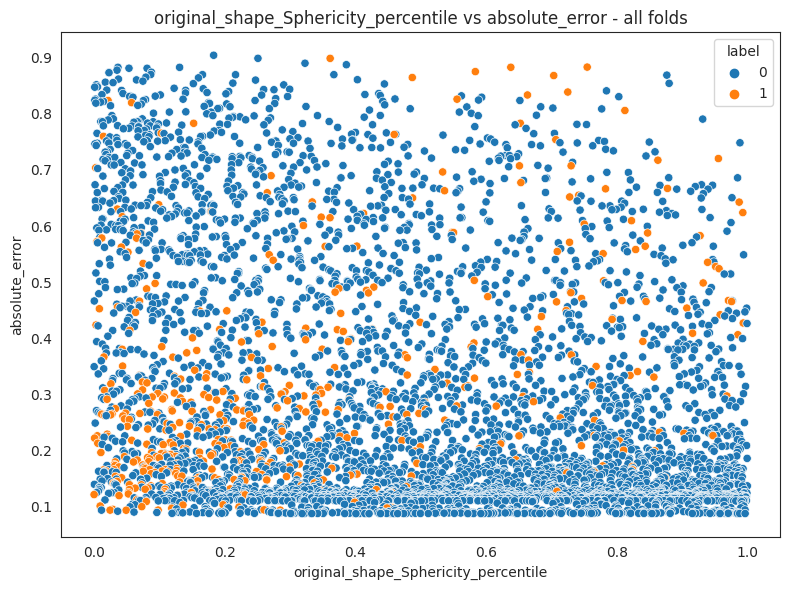

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_500_worst_predictions_in_all_folds.png


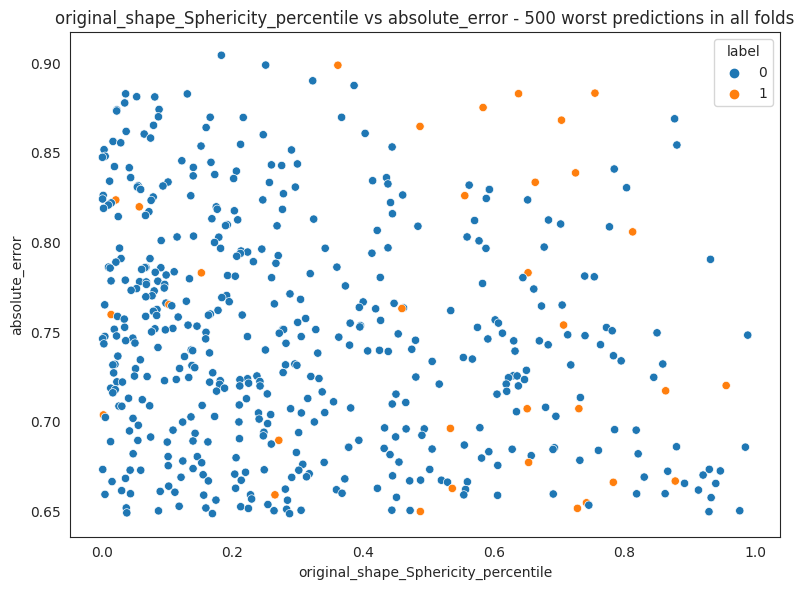

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_200_worst_predictions_in_fold_1.png


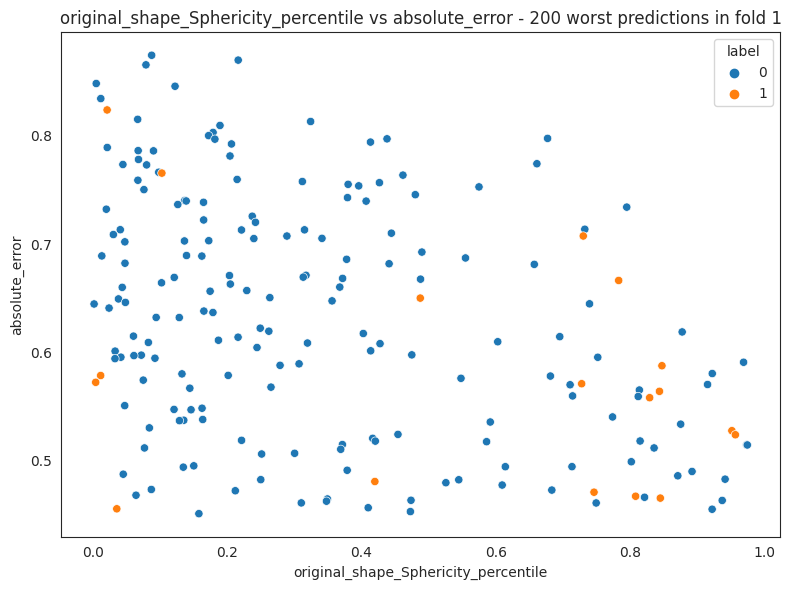

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_200_worst_predictions_in_fold_2.png


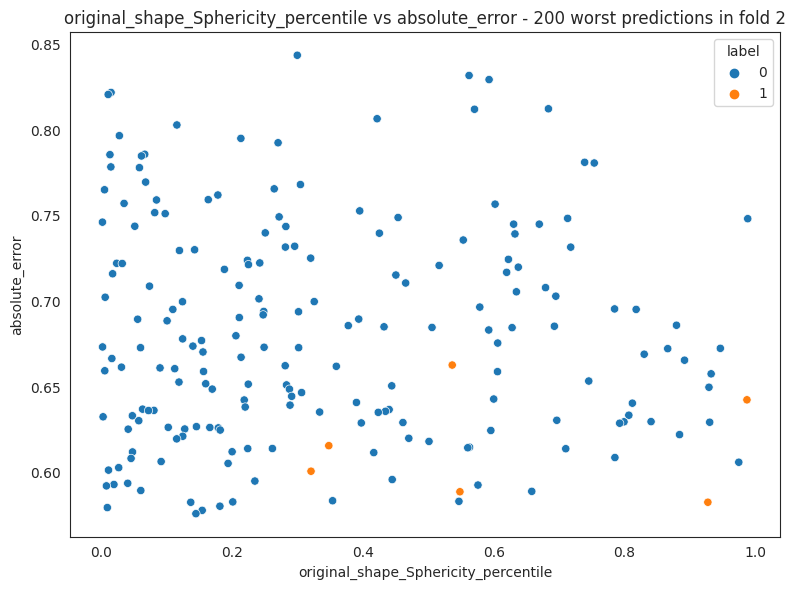

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_200_worst_predictions_in_fold_3.png


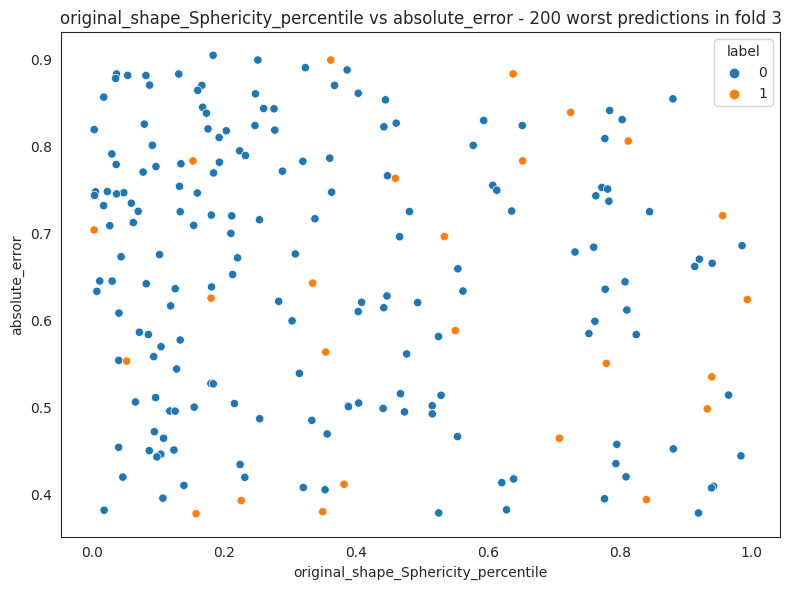

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_200_worst_predictions_in_fold_4.png


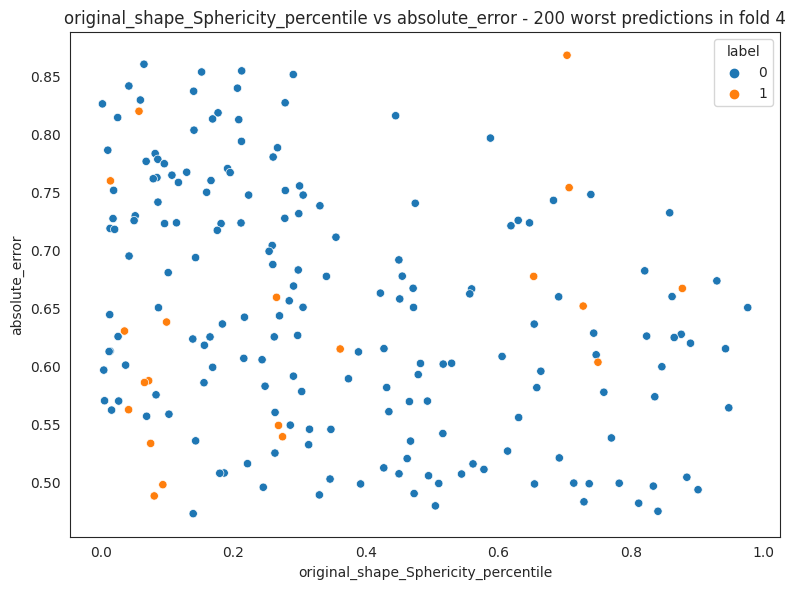

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_sphericity_scatterplot_200_worst_predictions_in_fold_5.png


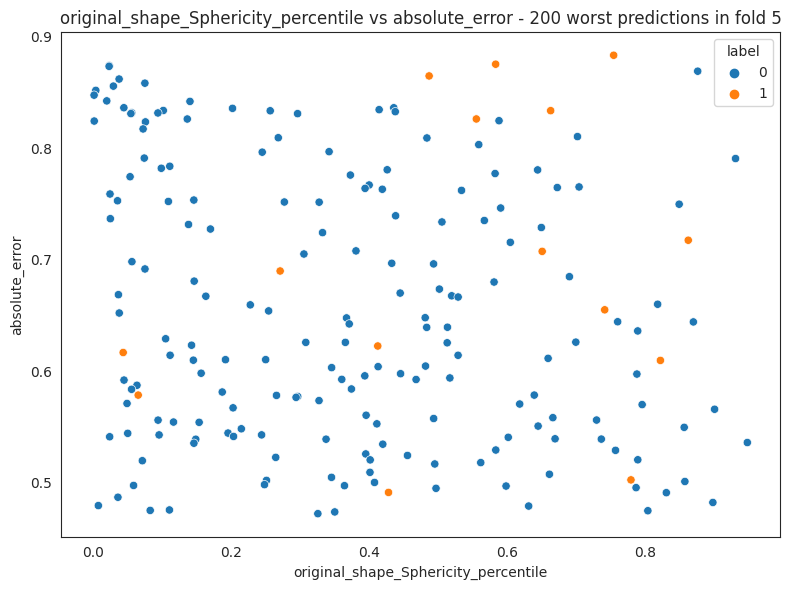

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_all_folds.png


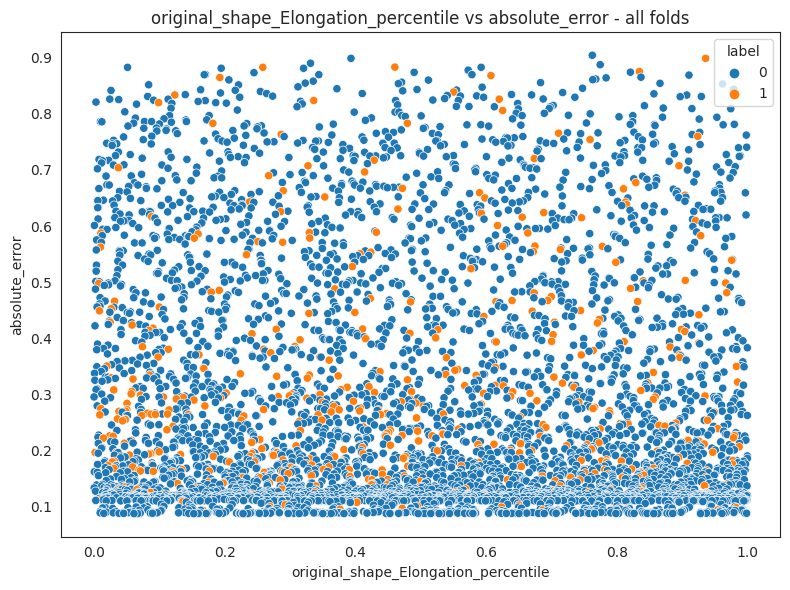

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_500_worst_predictions_in_all_folds.png


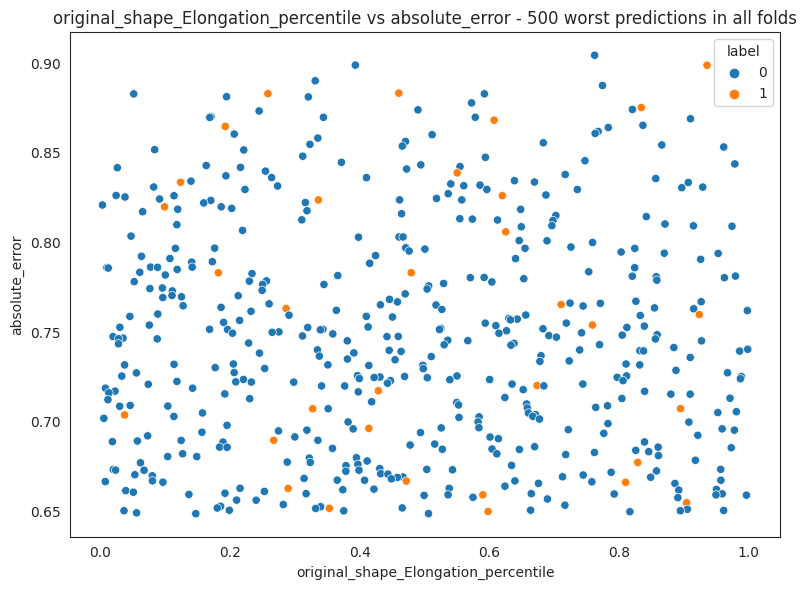

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_200_worst_predictions_in_fold_1.png


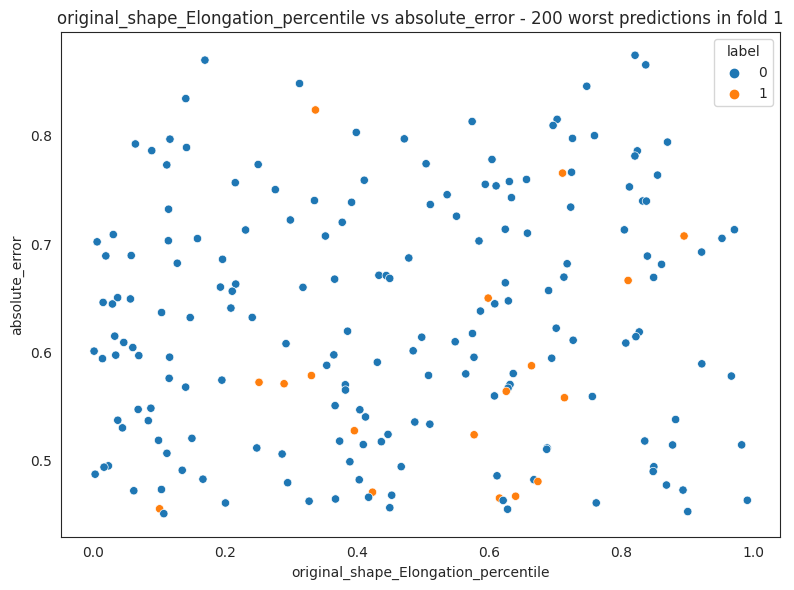

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_200_worst_predictions_in_fold_2.png


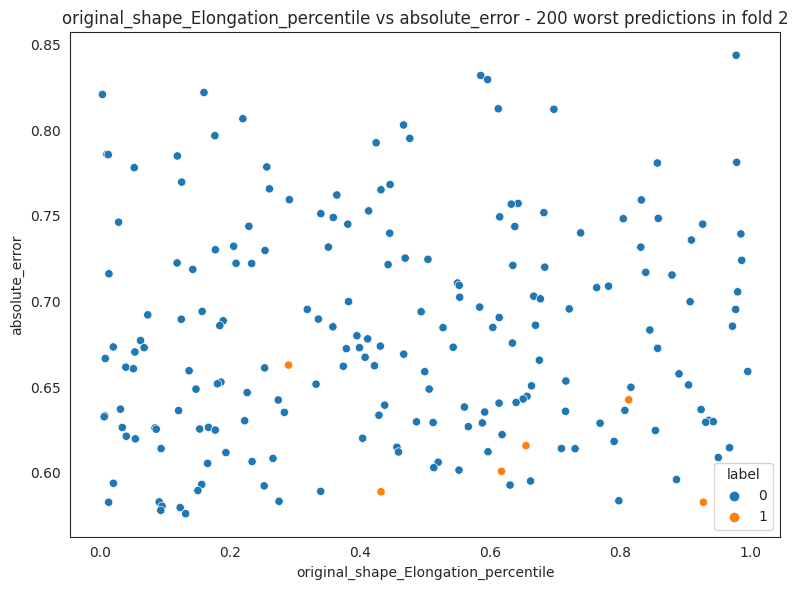

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_200_worst_predictions_in_fold_3.png


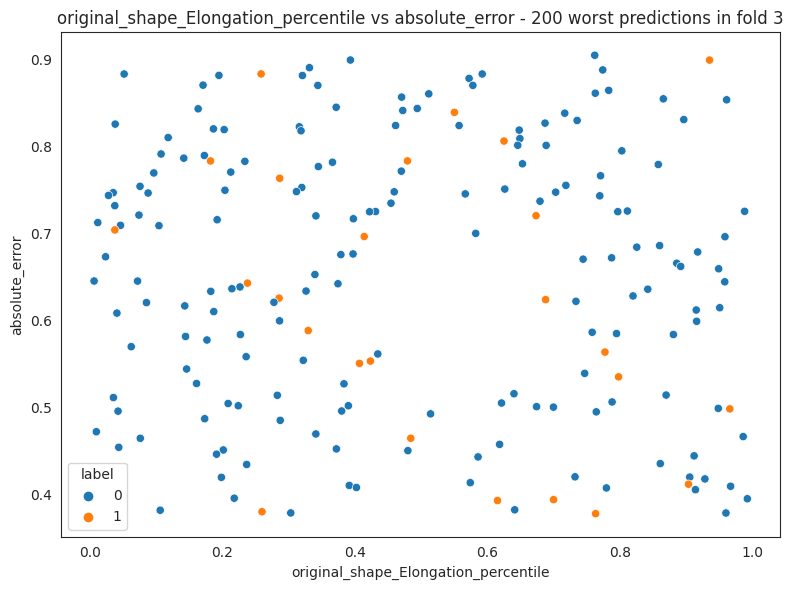

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_200_worst_predictions_in_fold_4.png


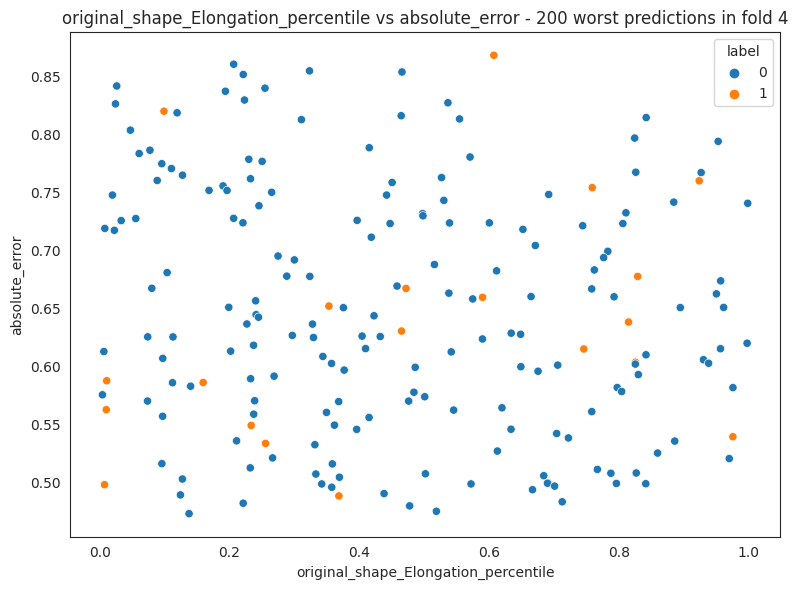

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_elongation_scatterplot_200_worst_predictions_in_fold_5.png


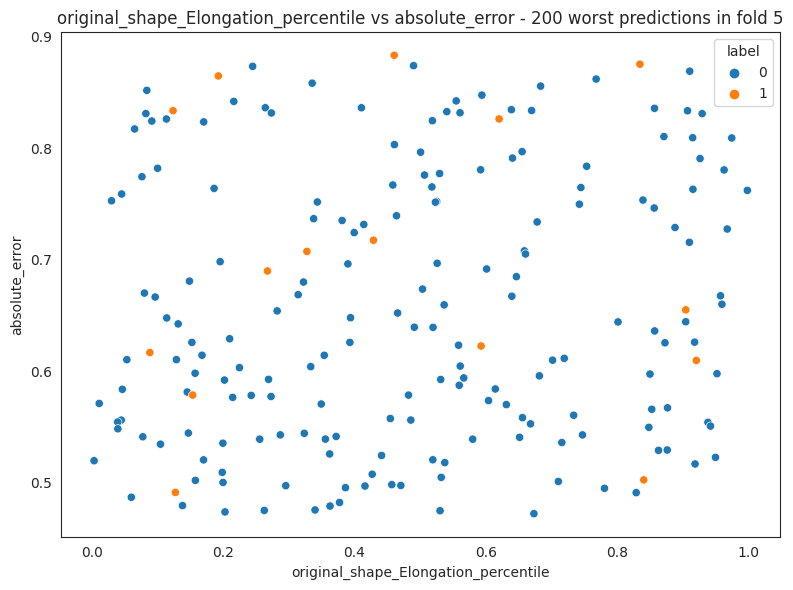

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_all_folds.png


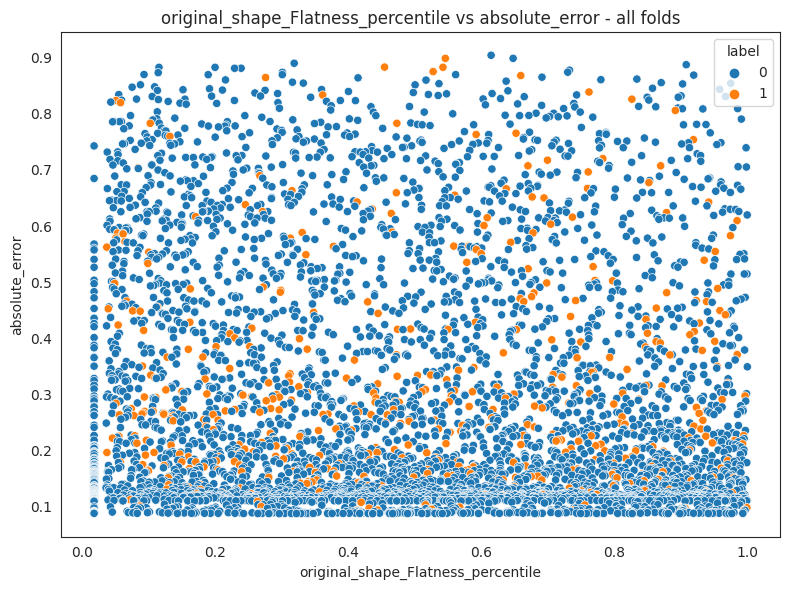

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_500_worst_predictions_in_all_folds.png


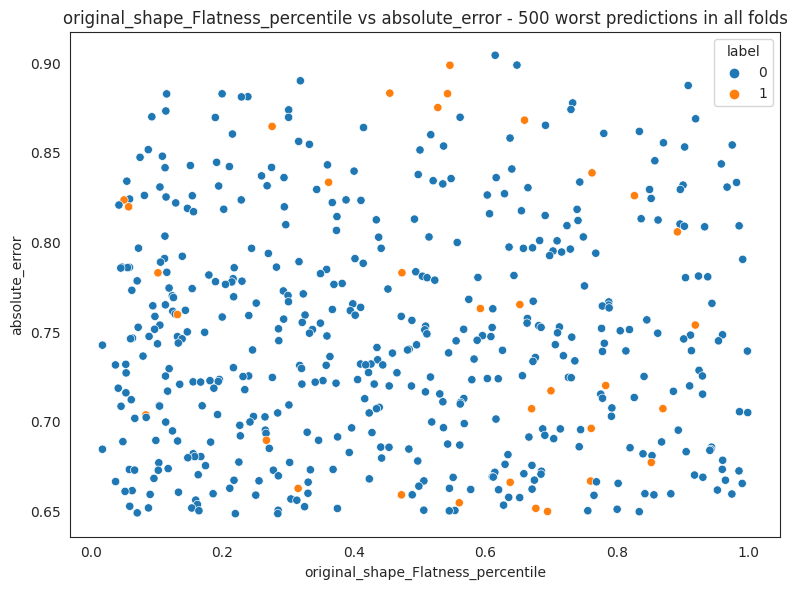

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_200_worst_predictions_in_fold_1.png


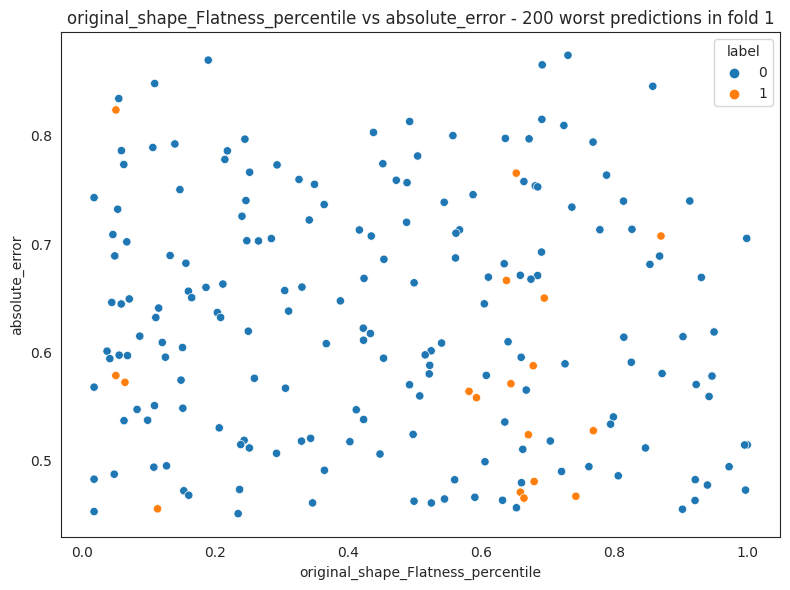

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_200_worst_predictions_in_fold_2.png


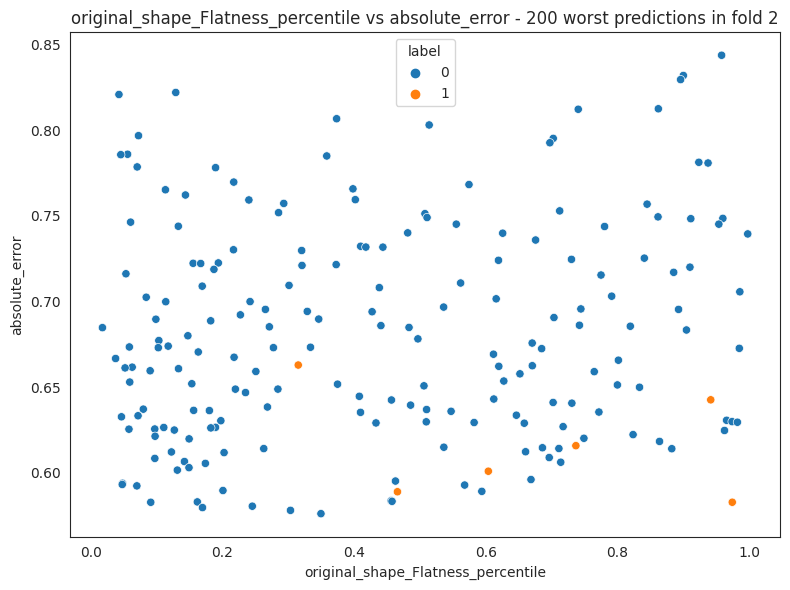

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_200_worst_predictions_in_fold_3.png


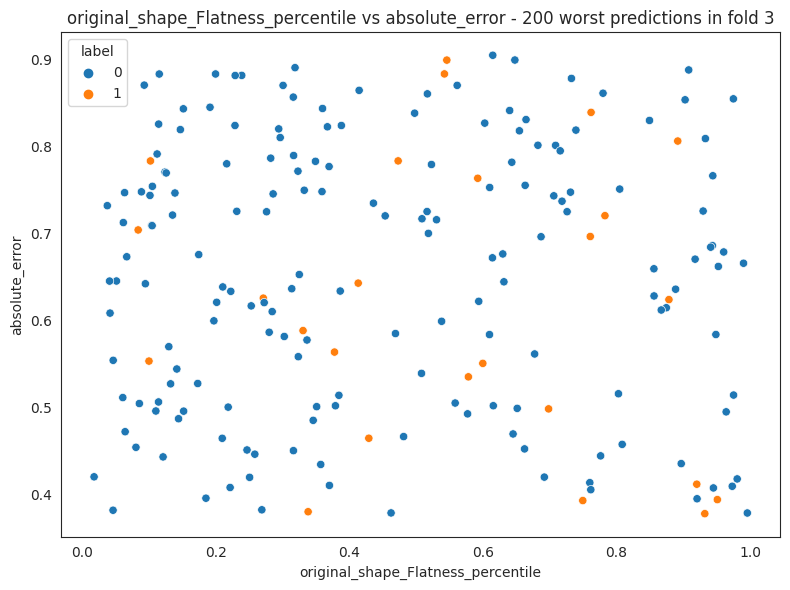

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_200_worst_predictions_in_fold_4.png


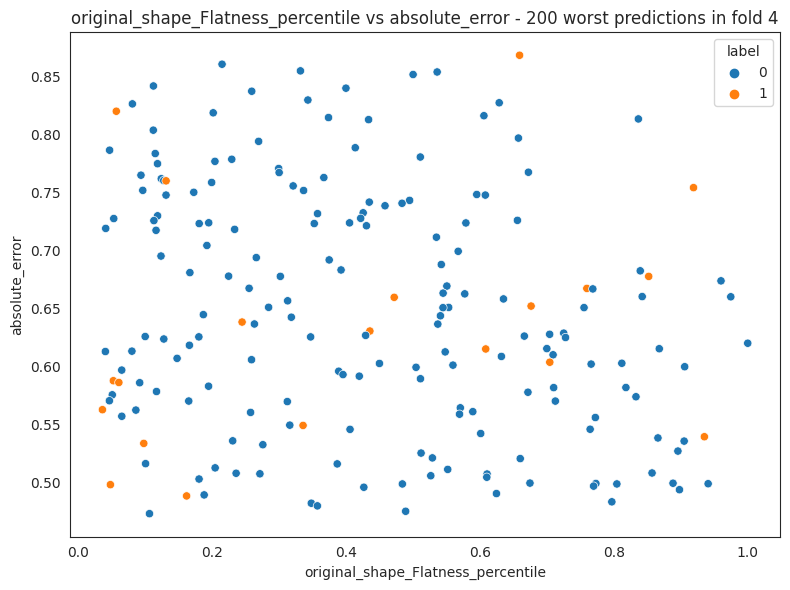

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_flatness_scatterplot_200_worst_predictions_in_fold_5.png


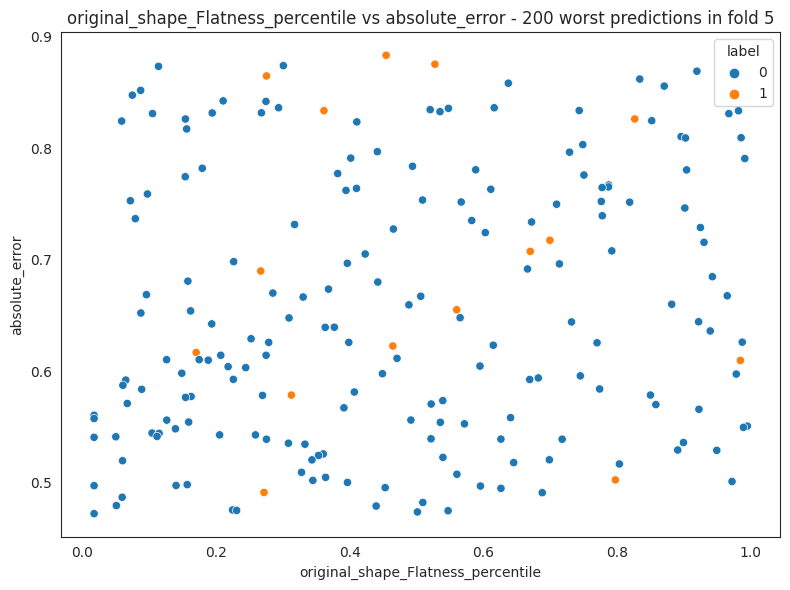

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_all_folds.png


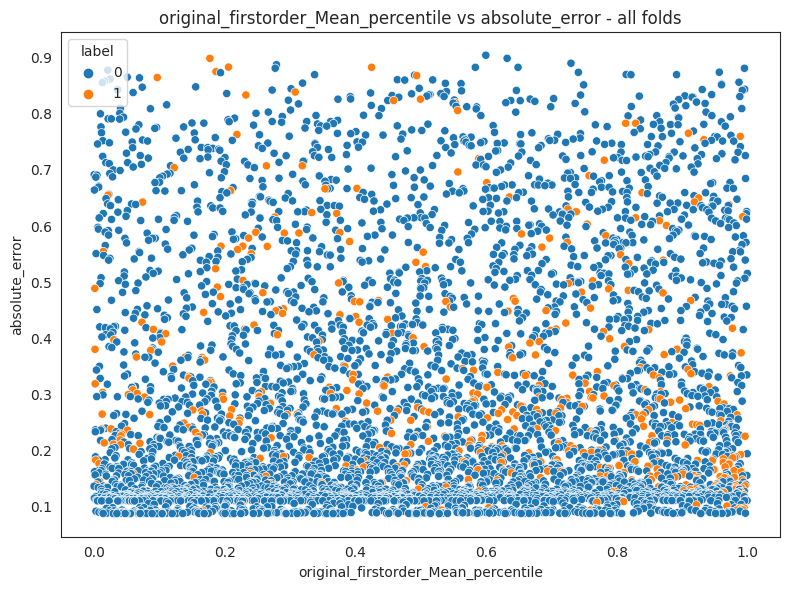

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_500_worst_predictions_in_all_folds.png


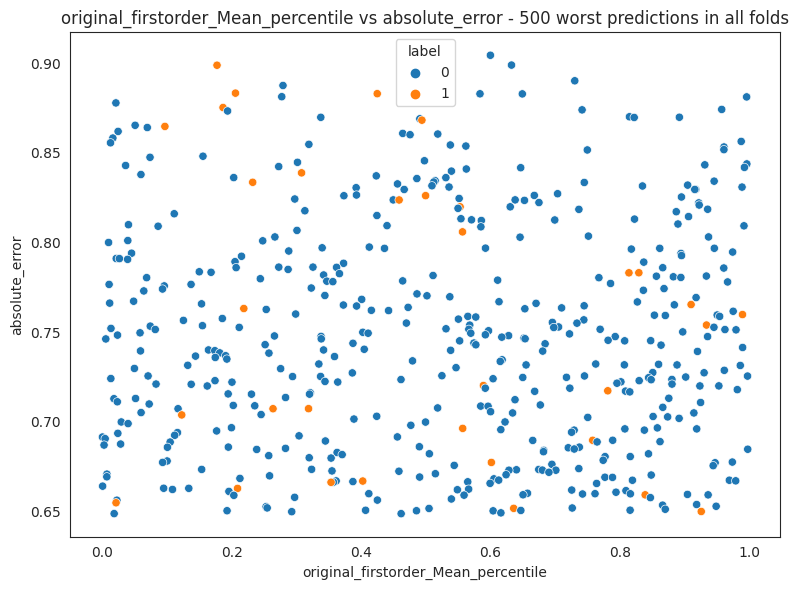

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_200_worst_predictions_in_fold_1.png


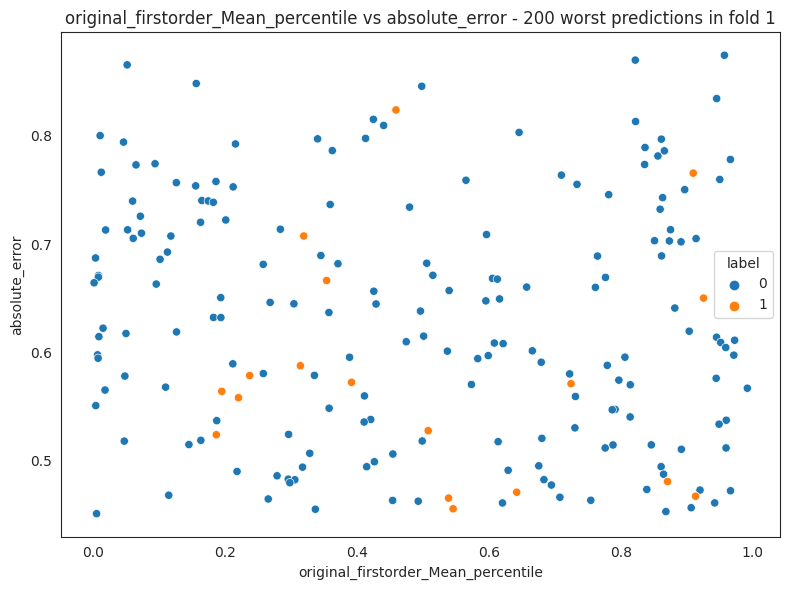

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_200_worst_predictions_in_fold_2.png


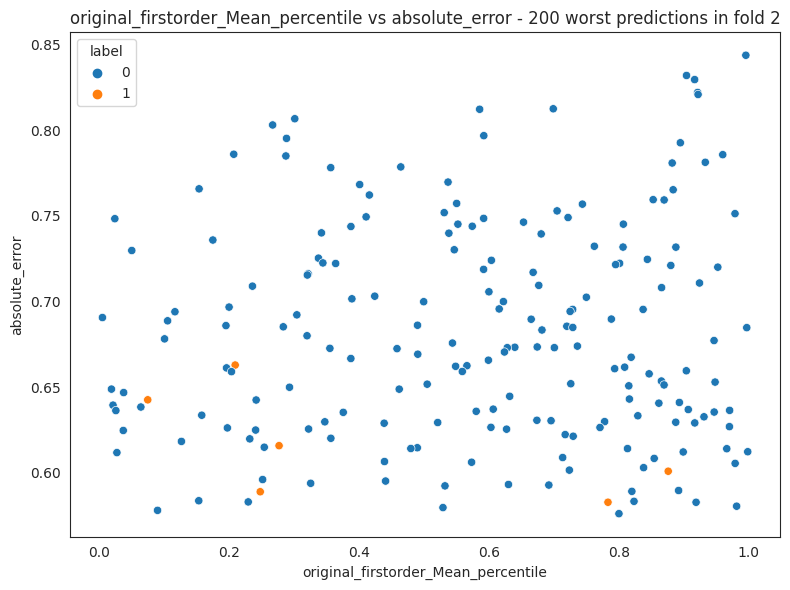

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_200_worst_predictions_in_fold_3.png


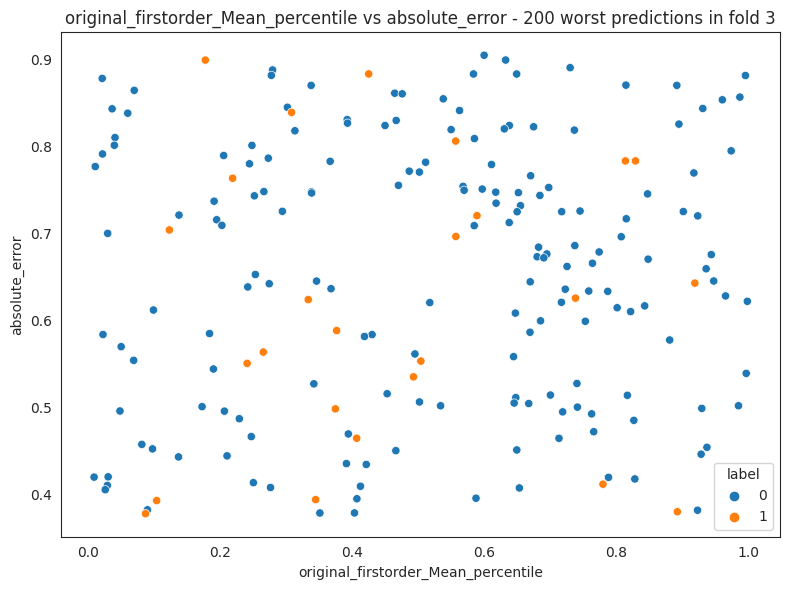

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_200_worst_predictions_in_fold_4.png


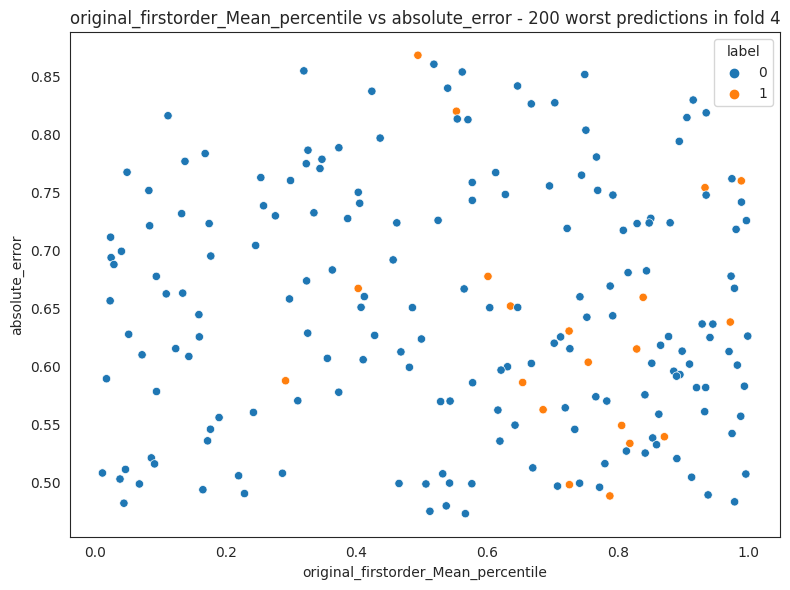

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_mean_scatterplot_200_worst_predictions_in_fold_5.png


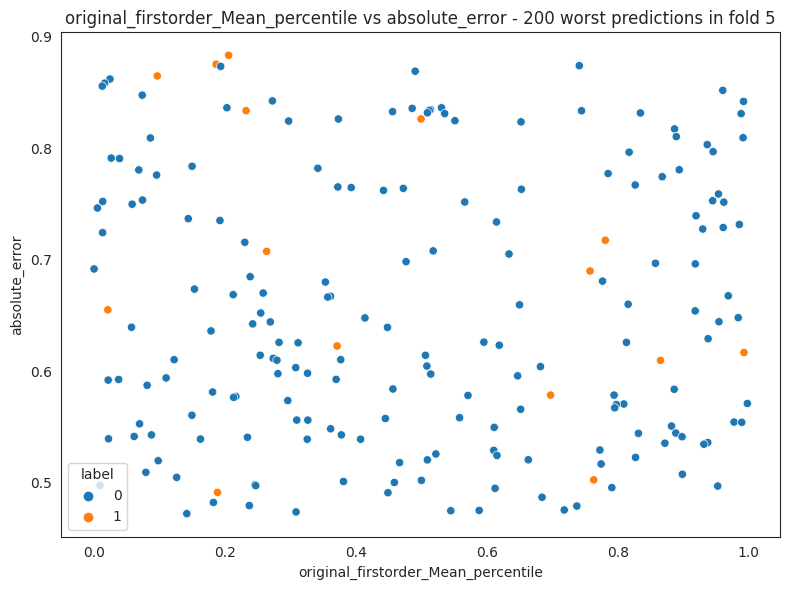

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_all_folds.png


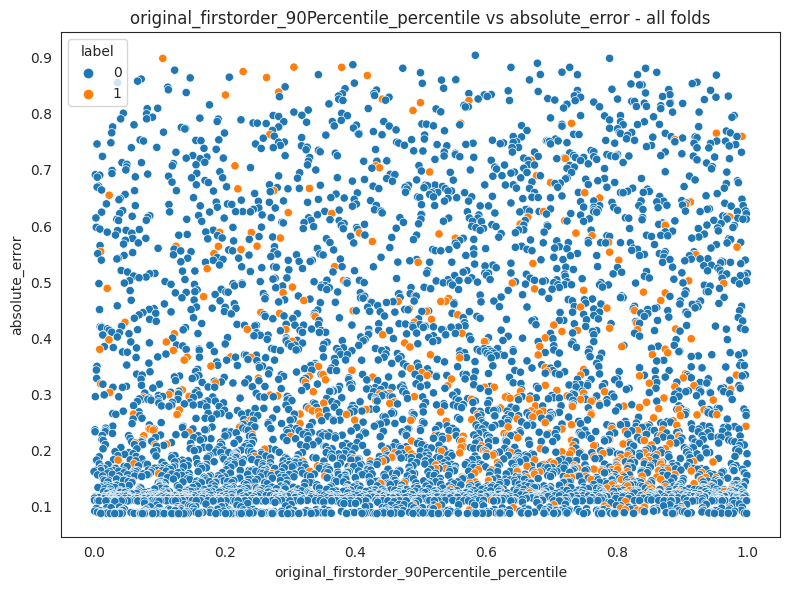

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_500_worst_predictions_in_all_folds.png


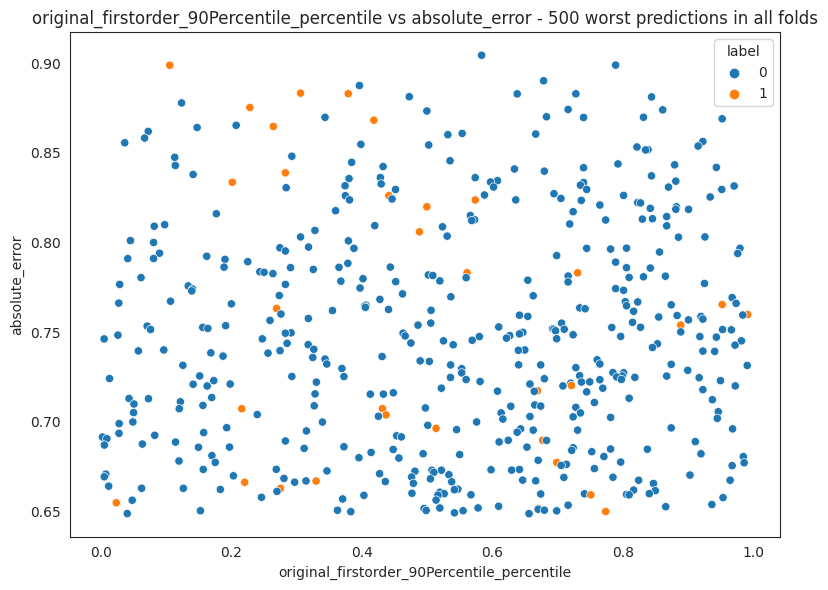

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_200_worst_predictions_in_fold_1.png


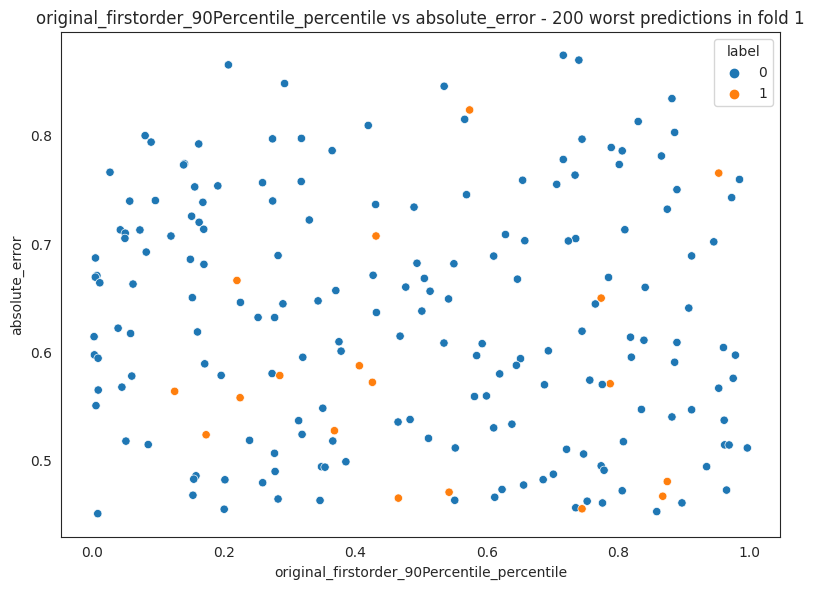

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_200_worst_predictions_in_fold_2.png


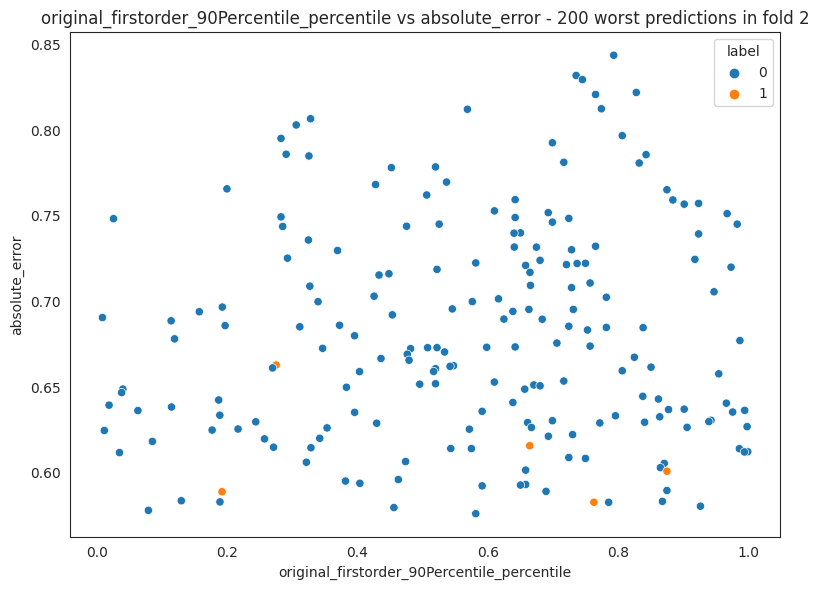

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_200_worst_predictions_in_fold_3.png


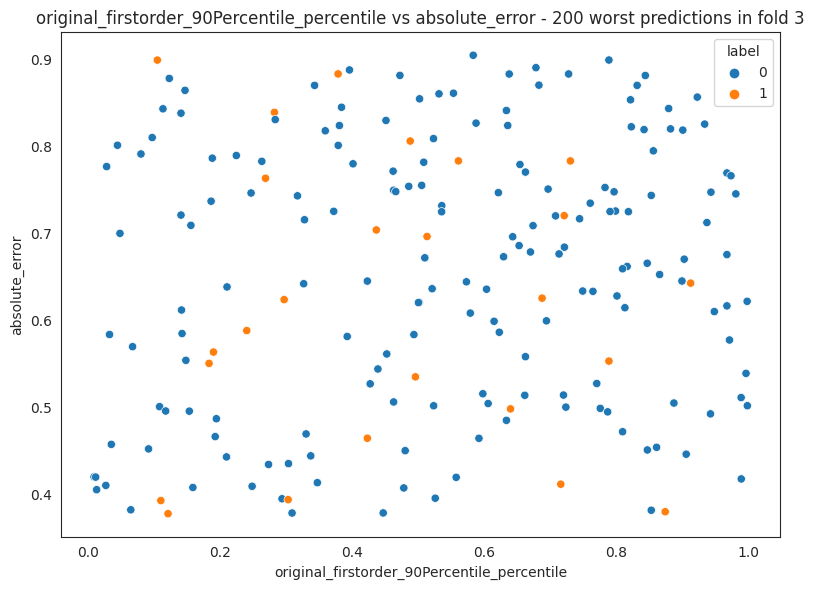

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_200_worst_predictions_in_fold_4.png


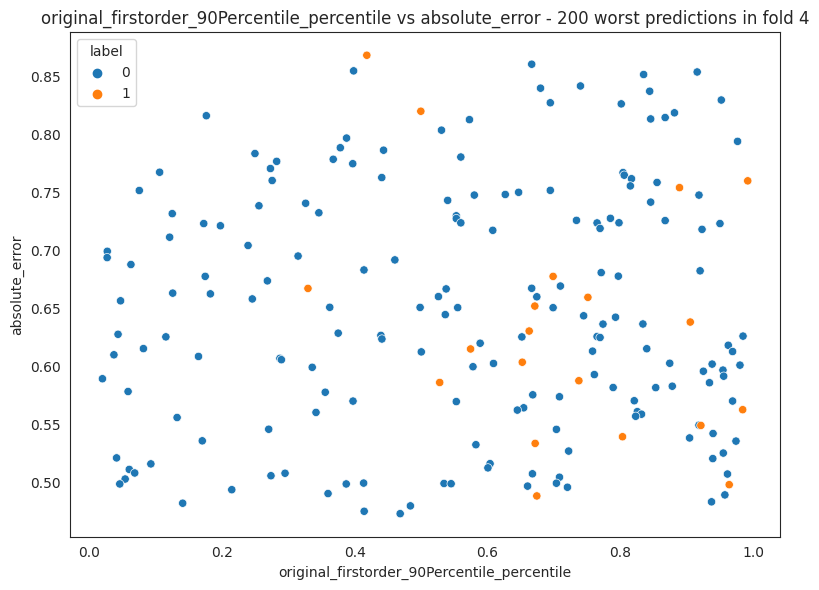

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_90th_percentile_scatterplot_200_worst_predictions_in_fold_5.png


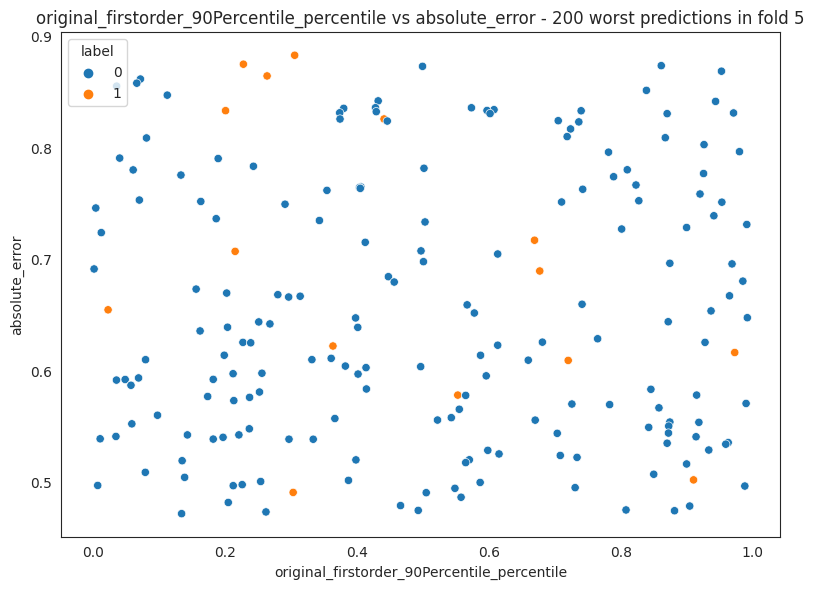

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_all_folds.png


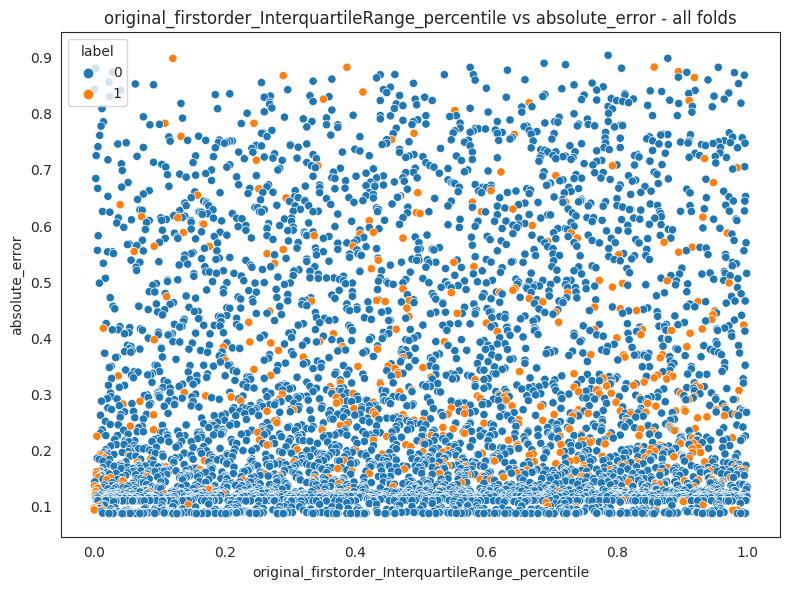

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_500_worst_predictions_in_all_folds.png


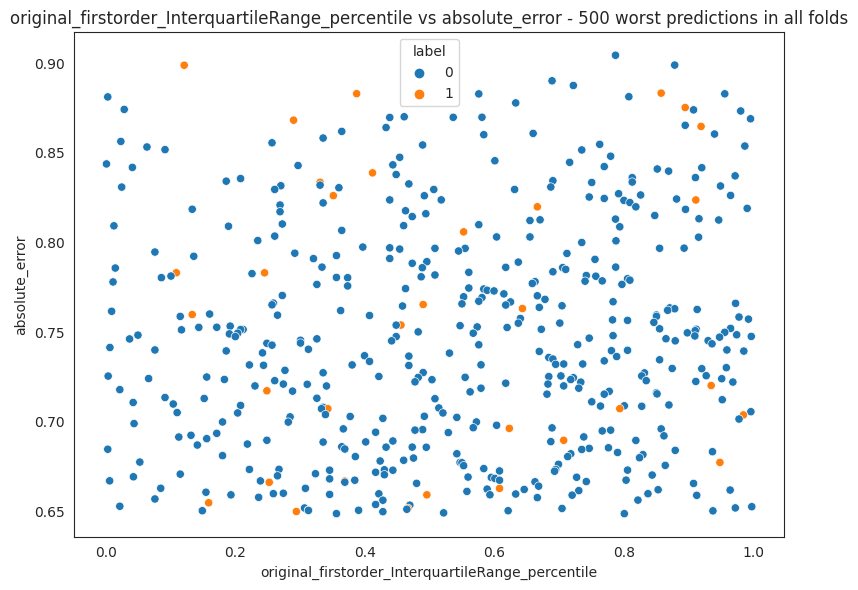

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_200_worst_predictions_in_fold_1.png


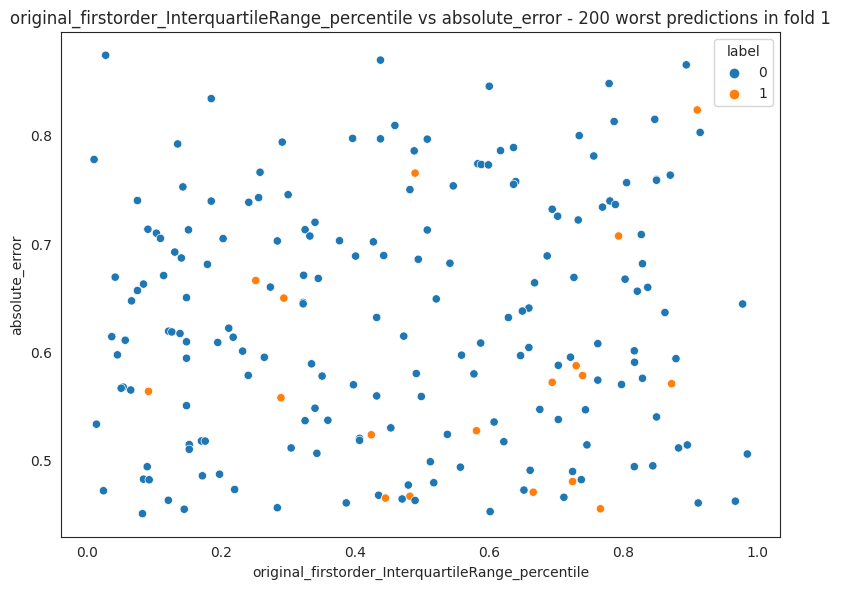

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_200_worst_predictions_in_fold_2.png


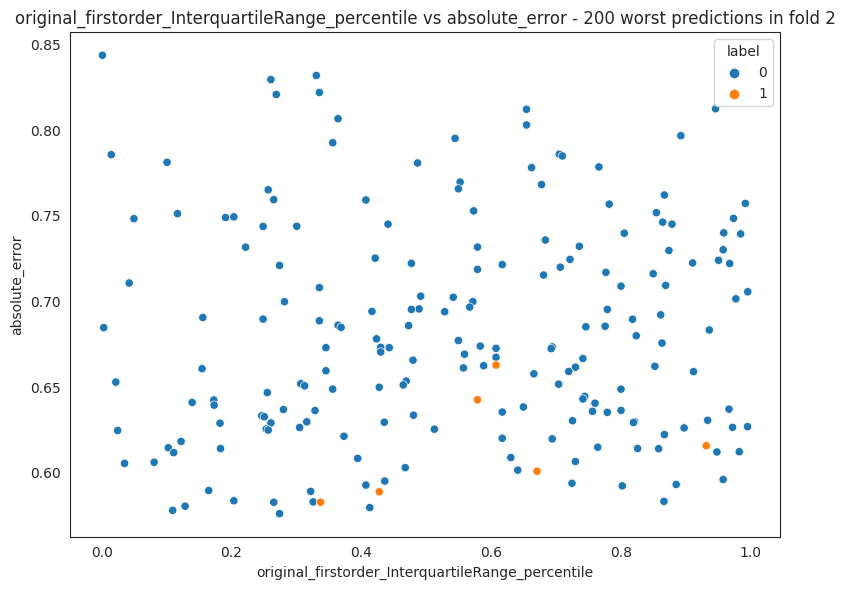

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_200_worst_predictions_in_fold_3.png


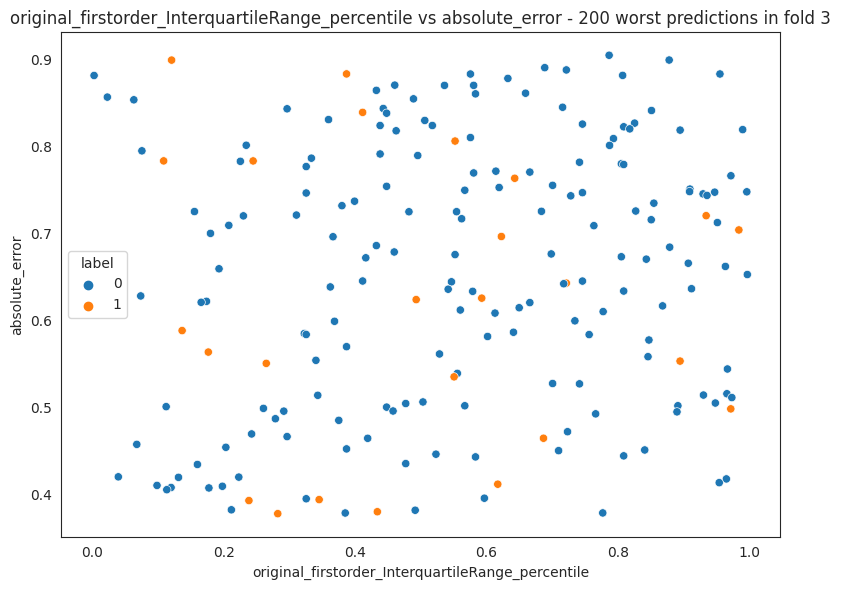

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_200_worst_predictions_in_fold_4.png


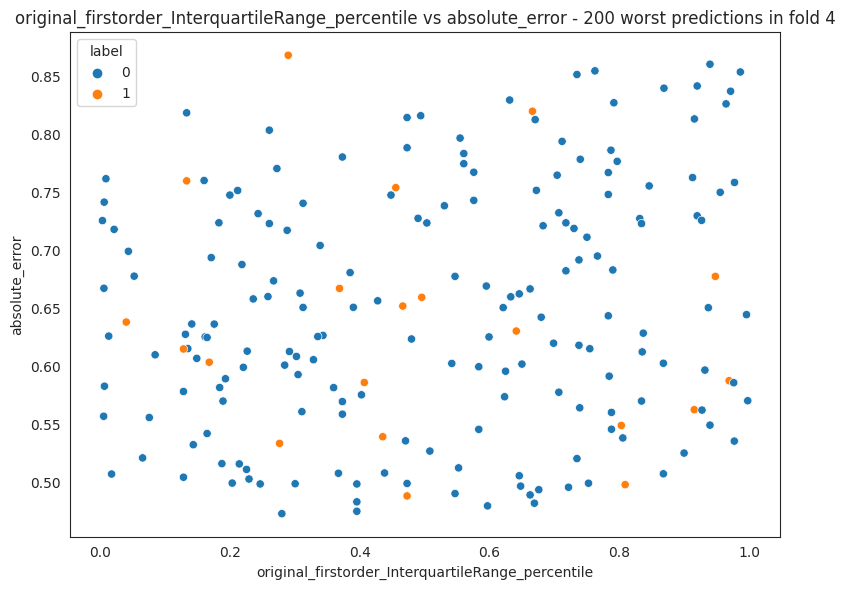

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_iqr_scatterplot_200_worst_predictions_in_fold_5.png


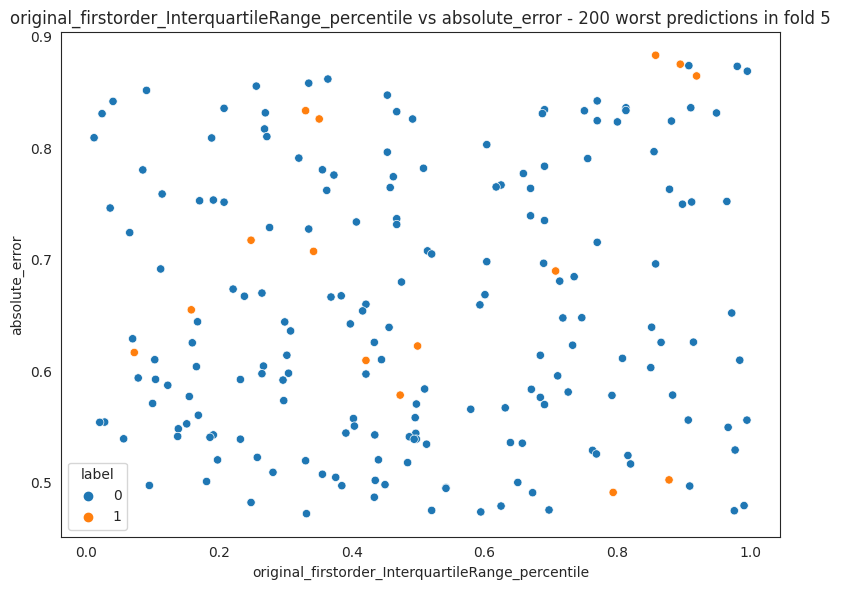

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_all_folds.png


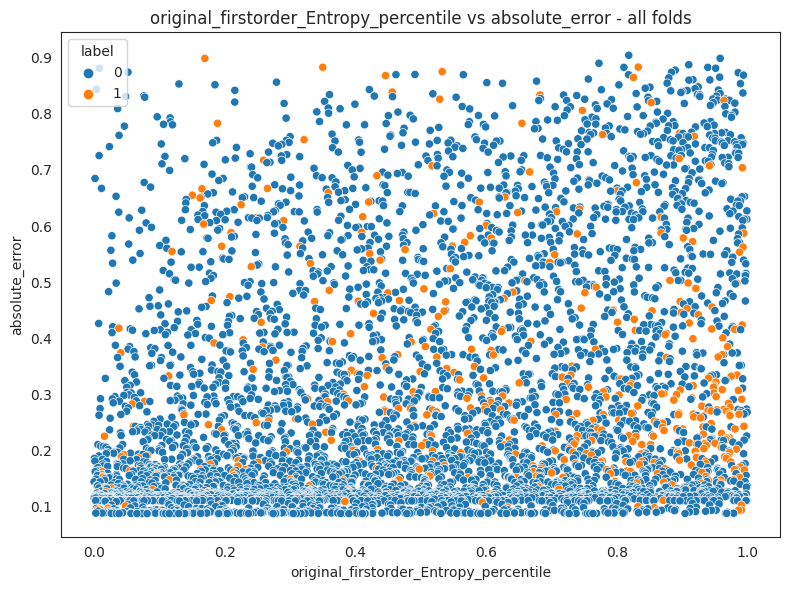

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_500_worst_predictions_in_all_folds.png


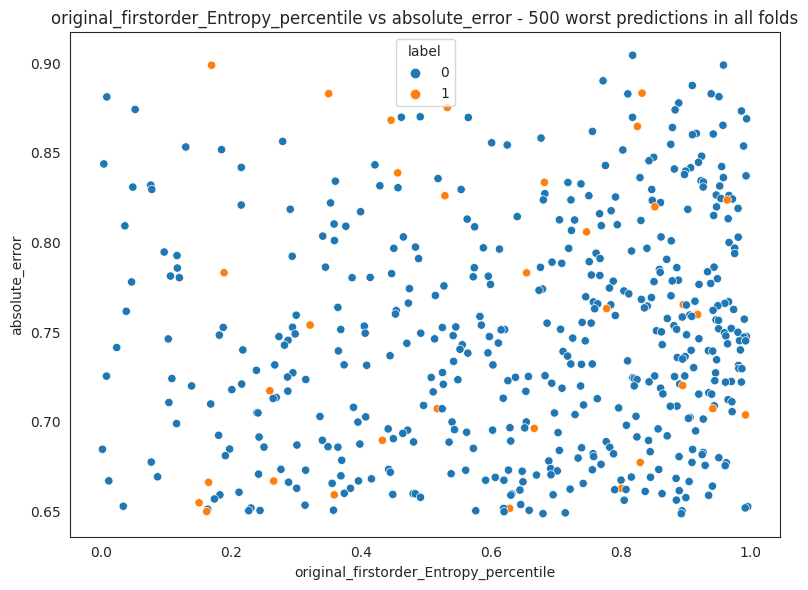

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_200_worst_predictions_in_fold_1.png


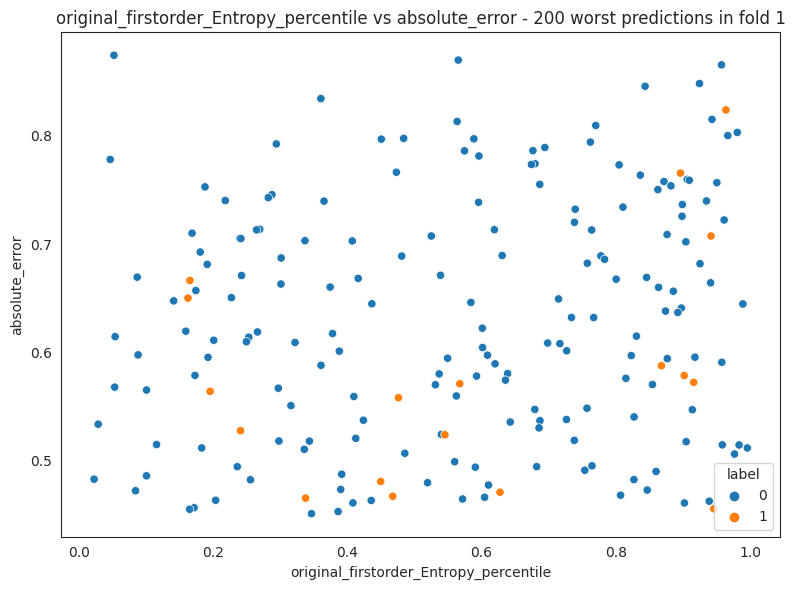

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_200_worst_predictions_in_fold_2.png


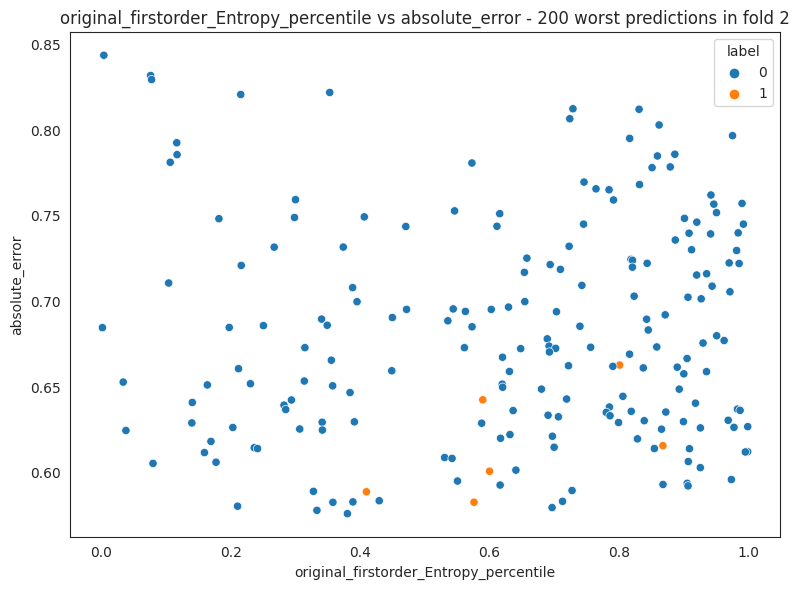

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_200_worst_predictions_in_fold_3.png


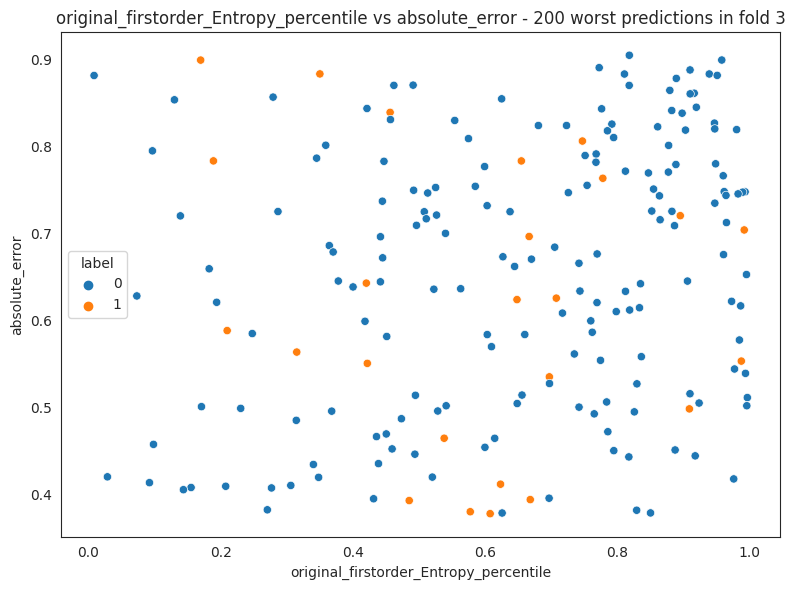

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_200_worst_predictions_in_fold_4.png


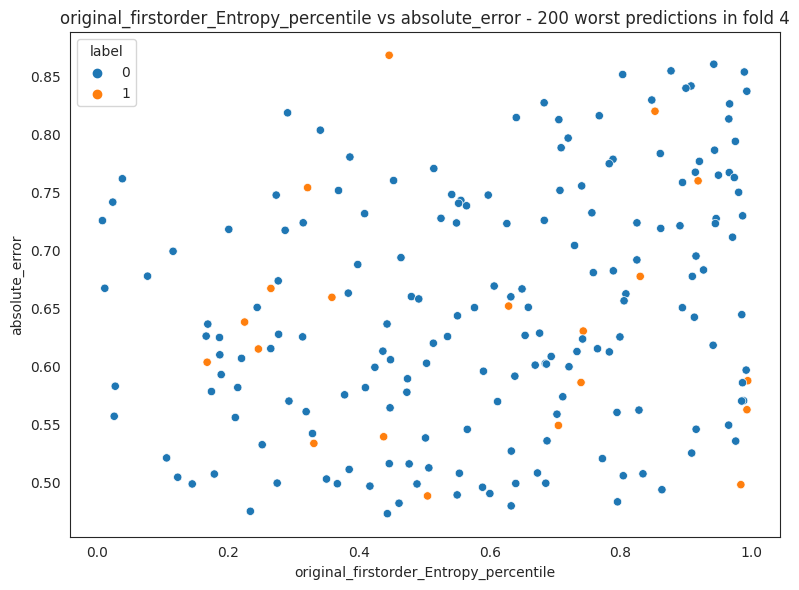

Scatterplot saved to /models/hiera-luna25/figures/radiomics/error_hu_entropy_scatterplot_200_worst_predictions_in_fold_5.png


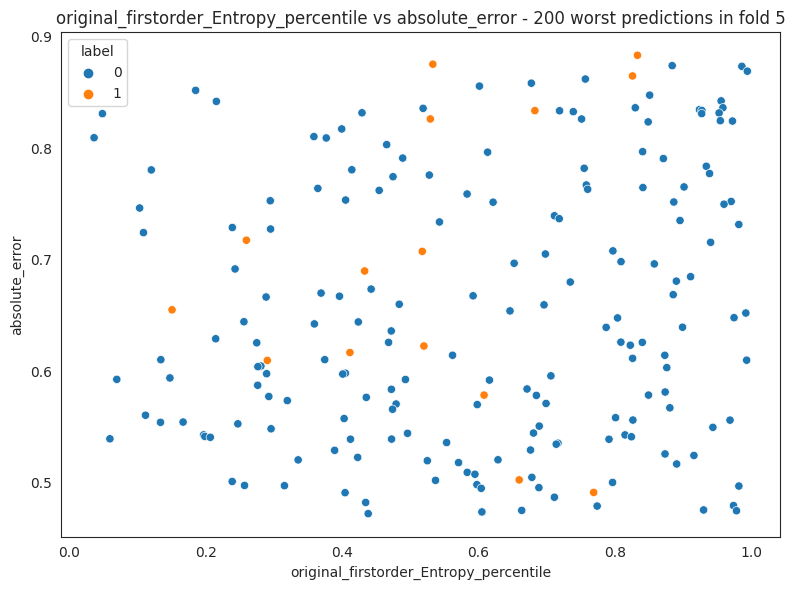

In [10]:
# interpretable subset of the PyRadiomics features computed on the MedSAM masks (size is covered by volume above)
radiomic_features = {
    "original_shape_Sphericity": "sphericity",
    "original_shape_Elongation": "elongation",
    "original_shape_Flatness": "flatness",
    "original_firstorder_Mean": "hu_mean",
    "original_firstorder_90Percentile": "hu_90th_percentile",
    "original_firstorder_InterquartileRange": "hu_iqr",
    "original_firstorder_Entropy": "hu_entropy",
}

df_radiomics = pd.read_csv(radiomics_csv_path, usecols=["AnnotationID", *radiomic_features])
# percentiles over all masks, as for volume_percentile
for feature in radiomic_features:
    df_radiomics[f"{feature}_percentile"] = df_radiomics[feature].rank(pct=True, method="average").round(4)
df_radiomics_predictions = pd.merge(df_annotations_volumes_predictions, df_radiomics, on="AnnotationID", how="left")
num_missing = df_radiomics_predictions[list(radiomic_features)[0]].isna().sum()
print(f"{num_missing} of {len(df_radiomics_predictions)} predictions have no radiomics and are dropped from the plots")

correlations = {
    name: df_radiomics_predictions[f"{feature}_percentile"].corr(df_radiomics_predictions["absolute_error"], method="spearman")
    for feature, name in radiomic_features.items()
}
correlations["volume"] = df_radiomics_predictions["volume_percentile"].corr(df_radiomics_predictions["absolute_error"], method="spearman")
print("Spearman correlation between feature percentile and absolute_error (all folds):")
display(pd.Series(correlations, name="spearman_rho").round(3).to_frame())

for feature, name in radiomic_features.items():
    plot_kwargs = dict(x=f"{feature}_percentile", name=name, save_dir=radiomics_figures_dir, save_worst_predictions=False)
    plot_error_feature_distribution(df_radiomics_predictions, **plot_kwargs)
    plot_error_feature_distribution(df_radiomics_predictions, num_worst_predictions=num_worst_predictions_all_folds, **plot_kwargs)
    for fold in range(1, 6):
        df_fold = df_radiomics_predictions[df_radiomics_predictions["fold"] == fold]
        plot_error_feature_distribution(df_fold, num_worst_predictions=num_worst_predictions_one_fold, plot_label=f"fold {fold}", **plot_kwargs)

### Edge Cases

0.8 quantile of sphere_radius_mm in all folds is 6.47586501407756


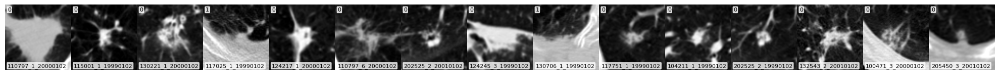

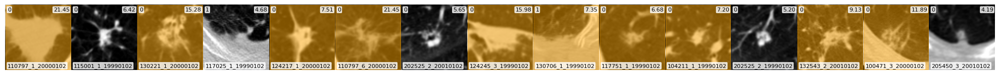

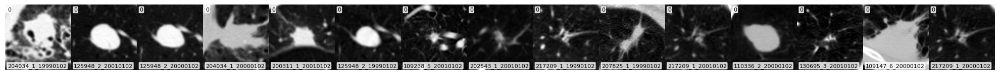

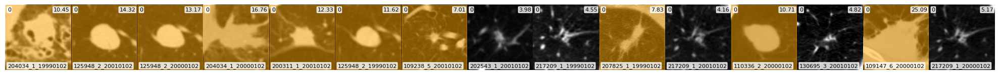

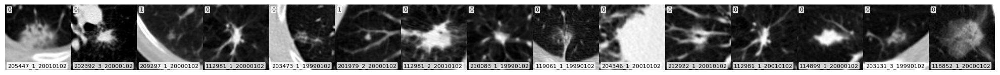

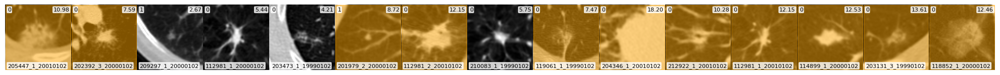

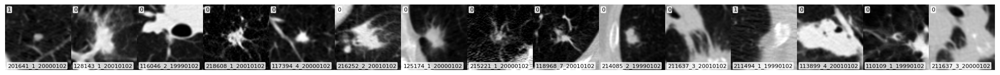

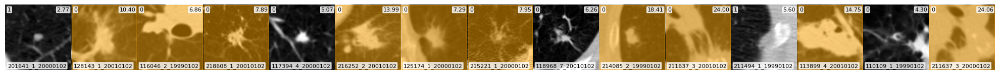

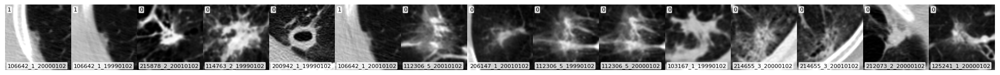

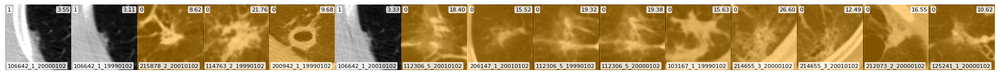

In [11]:
def plot_images(images, labels=None, annotation_ids=None, radius_mms=None, radius_mm_at_quantile=None, save_plot=True, plot_label=None):
    num_images, height, width = images.shape
    fig, axes = plt.subplots(1, num_images, figsize=(20, 3))
    for i, (ax, image) in enumerate(zip(axes, images)):
        ax.imshow(image, cmap="gray")

        bbox = dict(facecolor="white", alpha=0.8, boxstyle="round,pad=0.1")
        if labels is not None:
            ax.text(2, 2, f"{labels[i]}", fontsize=8, color="black", ha="left", va="top", bbox=bbox)
        if annotation_ids is not None:
            ax.text(2, height - 2, f"{annotation_ids[i]}", fontsize=8, color="black", ha="left", va="bottom", bbox=bbox)
        if radius_mms is not None:
            ax.text(width - 2, 2, f"{radius_mms[i]:.2f}", fontsize=8, color="black", ha="right", va="top", bbox=bbox)
            if radius_mm_at_quantile is not None and radius_mms[i] > radius_mm_at_quantile:
                rect_patch = Rectangle((0, 0), width - 1, height - 1, linewidth=1.0, edgecolor="orange", facecolor="orange", alpha=0.5, transform=ax.transData) 
                ax.add_patch(rect_patch)
        ax.axis("off")
    plt.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01, wspace=0, hspace=0)
    if save_plot:
        plt.savefig(figures_dir / f"{num_images}_worst_predictions_{plot_label}.png", dpi=300, bbox_inches="tight", pad_inches=0)
    plt.show()

num_images = 15
radius_quantile = 0.8
radius_mm_at_quantile = df_annotations_volumes_predictions["sphere_radius_mm"].quantile(radius_quantile)
print(f"{radius_quantile} quantile of sphere_radius_mm in all folds is {radius_mm_at_quantile}")
for fold in range(1, 6):
    worst_preds_csv_path = figures_dir / f"{num_worst_predictions_one_fold}_worst_predictions_in_fold_{fold}.csv"
    df_worst_preds = pd.read_csv(worst_preds_csv_path)
    df_images = df_worst_preds.head(num_images)
    df_images = df_images[["AnnotationID", "label", "sphere_radius_mm"]]
    data_loader = get_data_loader(
        "/datasets/slow/LUNA25/luna25_nodule_blocks",
        df_images,
        mode=config.MODE,
        workers=0,
        batch_size=num_images,
        rotations=None,
        translations=None,
        size_mm=config.SIZE_MM,
        size_px=config.SIZE_PX,
    )
    for data in data_loader:
        images, labels, annotation_ids = data["image"].numpy(), data["label"].squeeze().numpy().tolist(), data["ID"]
        images = images[:, 0, images.shape[2] // 2, :, :]
        radius_mms = df_images[df_images.AnnotationID.isin(annotation_ids)].sphere_radius_mm.values
        plot_images(images, labels, annotation_ids, plot_label=f"fold_{fold}_no_radius")
        plot_images(images, labels, annotation_ids, radius_mms, radius_mm_at_quantile, plot_label=f"fold_{fold}")

# Evaluate

In [12]:
# https://github.com/DIAGNijmegen/luna25-evaluation-public
def calculate_auc(y_true, y_pred):
    auc = roc_auc_score(y_true, y_pred)

    # Bootstrapping for 95% confidence intervals
    n_bootstraps = 1000
    rng = np.random.RandomState(seed=42)
    bootstrapped_aucs = []

    for _ in range(n_bootstraps):
        # Resample the data
        indices = rng.choice(len(y_true), len(y_true), replace=True)
        if len(np.unique(y_true.iloc[indices])) < 2:
            # Skip this resample if only one class is present
            continue
        score = roc_auc_score(y_true.iloc[indices], y_pred.iloc[indices])
        bootstrapped_aucs.append(score)

    # Calculate the confidence intervals
    ci_lower = np.percentile(bootstrapped_aucs, 2.5)
    ci_upper = np.percentile(bootstrapped_aucs, 97.5)

    return {"auc": auc, "ci_lower": ci_lower, "ci_upper": ci_upper}

def calculate_sensitivity(y_true, y_pred):
    """
    Computes the sensitivity (recall) at 95% specificity for a classifier.
    
    Parameters:
        y_true (array-like): Ground truth binary labels (0 = benign, 1 = malignant).
        y_pred (array-like): Predicted probability scores from the classifier.

    Returns:
        float: Sensitivity (recall) at 95% specificity.
        float: Decision threshold used to achieve 95% specificity.
    """
    # Compute ROC curve
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    
    # Find the threshold corresponding to 95% specificity (FPR = 1 - specificity)
    target_fpr = 1 - 0.95  # 5% false positive rate
    idx = np.where(fpr <= target_fpr)[0][-1]  # Get the last index where FPR <= 5%
    
    # Extract sensitivity (TPR) and threshold
    sensitivity = tpr[idx]

    return {"sensitivity": sensitivity}

def calculate_specificity(y_true, y_pred):
    """
    Computes the specificity at 95% sensitivity for a classifier.
    
    Parameters:
        y_true (array-like): Ground truth binary labels (0 = benign, 1 = malignant).
        y_pred (array-like): Predicted probability scores from the classifier.

    Returns:
        float: Specificity at 95% sensitivity.
        float: Decision threshold used to achieve 95% sensitivity.
    """
    # Compute ROC curve
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    
    # Find the threshold corresponding to 95% sensitivity (TPR = 0.95)
    target_tpr = 0.95  # Sensitivity (TPR) threshold
    idx = np.where(tpr >= target_tpr)[0][0]  # Get first index where TPR >= 95%
    
    # Extract specificity (1 - FPR) and threshold
    specificity = 1 - fpr[idx]
    
    return {"specificity": specificity}

results = {"Fold": [], "AUC": [], "Sensitivity": [], "Specificity": []}
for fold in range(1, 6):
    df_fold = df_annotations_volumes_predictions[df_annotations_volumes_predictions["fold"] == fold]
    labels = df_fold["label"]
    preds = df_fold["probability"]
    results["Fold"].append(fold)
    results["AUC"].append(calculate_auc(labels, preds)["auc"])
    results["Sensitivity"].append(calculate_sensitivity(labels, preds)["sensitivity"])
    results["Specificity"].append(calculate_specificity(labels, preds)["specificity"])
results = pd.DataFrame(results)
display(results)
print(f"Avg AUC: {results['AUC'].mean():.4f}")
print(f"Avg Sensitivity: {results['Sensitivity'].mean():.2f}")
print(f"Avg Specificity: {results['Specificity'].mean():.2f}")


,Fold,AUC,Sensitivity,Specificity
0,1,0.902475,0.381443,0.702517
1,2,0.890164,0.494118,0.583429
2,3,0.912684,0.526316,0.690200
3,4,0.887039,0.419355,0.681332
4,5,0.900321,0.568182,0.488229


Avg AUC: 0.8985
Avg Sensitivity: 0.48
Avg Specificity: 0.63


ROC curves saved to /models/hiera-luna25/figures/roc_curves_5_fold.png


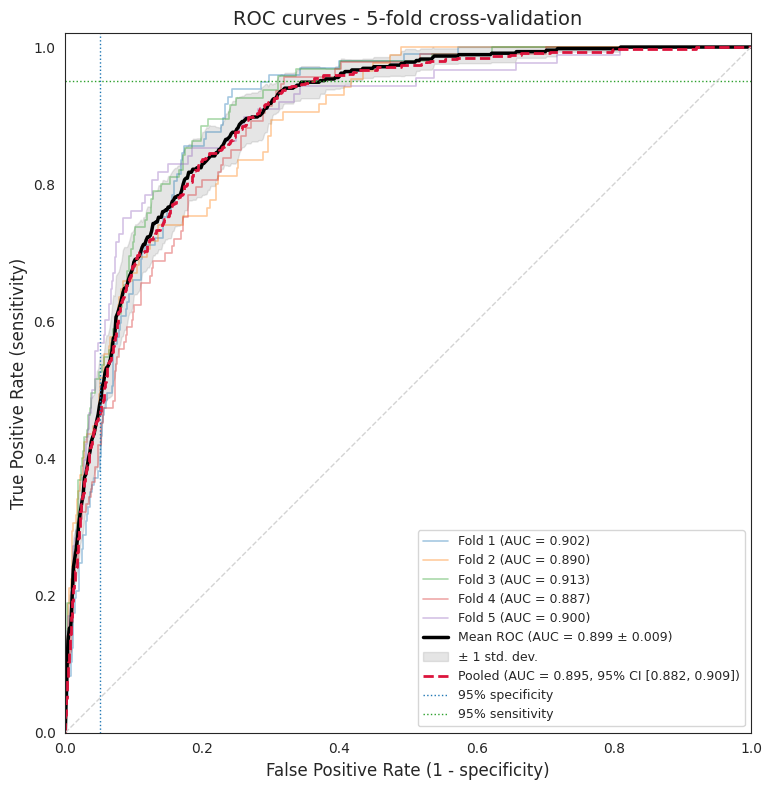

In [13]:
def plot_roc_curves(df, save_plot=True):
    fig, ax = plt.subplots(figsize=(8, 8))
    mean_fpr = np.linspace(0, 1, 501)
    tprs = []
    aucs = []
    for fold in sorted(df["fold"].unique()):
        df_fold = df[df["fold"] == fold]
        fpr, tpr, _ = roc_curve(df_fold["label"], df_fold["probability"])
        fold_auc = roc_auc_score(df_fold["label"], df_fold["probability"])
        aucs.append(fold_auc)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0
        ax.plot(fpr, tpr, alpha=0.4, lw=1.2, label=f"Fold {fold} (AUC = {fold_auc:.3f})")

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(tprs, axis=0)
    ax.plot(mean_fpr, mean_tpr, color="black", lw=2.5,
            label=f"Mean ROC (AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f})")
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0), np.minimum(mean_tpr + std_tpr, 1),
                    color="grey", alpha=0.2, label="± 1 std. dev.")

    pooled = calculate_auc(df["label"], df["probability"])
    fpr, tpr, _ = roc_curve(df["label"], df["probability"])
    ax.plot(fpr, tpr, color="crimson", lw=2, ls="--",
            label=f"Pooled (AUC = {pooled['auc']:.3f}, 95% CI [{pooled['ci_lower']:.3f}, {pooled['ci_upper']:.3f}])")

    ax.axvline(0.05, color="tab:blue", ls=":", lw=1, label="95% specificity")
    ax.axhline(0.95, color="tab:green", ls=":", lw=1, label="95% sensitivity")
    ax.plot([0, 1], [0, 1], color="lightgrey", ls="--", lw=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate (1 - specificity)", fontsize=12)
    ax.set_ylabel("True Positive Rate (sensitivity)", fontsize=12)
    ax.set_title("ROC curves - 5-fold cross-validation", fontsize=14)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_aspect("equal")
    plt.tight_layout()
    if save_plot:
        save_path = figures_dir / "roc_curves_5_fold.png"
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"ROC curves saved to {save_path}")
    plt.show()

plot_roc_curves(df_annotations_volumes_predictions)
